# Проект: Рынок общественного питания

Автор: Минько Никита

Дата: 2026-08-26

Инвесторы из фонда `Shut Up and Take My Money` решили попробовать себя в новой области и открыть заведение общественного питания в Москве. Заказчики ещё не знают, что это будет за место: кафе, ресторан или бар. Расположение, меню и цены пока тоже обсуждаются. Поэтому заказчики обратились к нам.

**Цель проекта** — провести исследовательский анализ рынка Москвы, результаты которого помогут в выборе подходящего инвесторам места.

Для работы над проектом нам доступны два датасета с заведениями общественного питания Москвы, составленные на основе данных сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Информация, размещённая в сервисе Яндекс Бизнес, могла быть добавлена пользователями или найдена в общедоступных источниках. Она носит исключительно справочный характер.

### Предварительное описание данных:

Датасет `rest_info.csv` содержит информацию о заведениях общественного питания:
- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение, например Центральный административный округ;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
        0 — заведение не является сетевым;
        1 — заведение является сетевым.
- `seats` — количество посадочных мест.

Датасет `rest_price.csv` содержит информацию о среднем чеке в заведениях общественного питания:
- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — хранит среднюю стоимость заказа в виде диапазона, например:
        «Средний счёт: 1000–1500 ₽»;
        «Цена чашки капучино: 130–220 ₽»;
        «Цена бокала пива: 400–600 ₽» и так далее;
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:
        Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
        Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
        Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:
        Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
        Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
        Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

<a id="Содержание"></a>
### Содержание

1. [Загрузка данных и знакомство с ними](#Загрузка-данных-и-знакомство-с-ними)
    - [Знакомство с `rest_info`](#Знакомство-с-rest_info)
    - [Знакомство с `rest_price`](#Знакомство-с-rest_price)
    - [Объединение датафреймов](#Объединение-датафреймов)
    - [Результат знакомства с данными](#Результат-знакомства-с-данными)
2. [Предобработка данных](#Предобработка-данных)
    - [Тип данных](#Тип-данных)
    - [Пропуски](#Пропуски)
    - [Явные и неявные дубликаты](#Явные-и-неявные-дубликаты)
    - [Новый столбец `is_24_7`](#Новый-столбец-is_24_7)
    - [Результат предобработки данных](#Результат-предобработки-данных)
3. [Исследовательский анализ данных](#Исследовательский-анализ-данных)
    - [Распределение заведений по категориям](#Распределение-заведений-по-категориям)
    - [Распределение заведений по административным районам](#Распределение-заведений-по-административным-районам)
    - [Распределение заведений по категориям в Центральном административном округе](#Распределение-заведений-по-категориям-в-Центральном-административном-округе)
    - [Соотношение сетевых и несетевых заведений в целом и в разрезе категорий](#Соотношение-сетевых-и-несетевых-заведений-в-целом-и-в-разрезе-категорий)
    - [Распределение количества посадочных мест в заведениях по категориям](#Распределение-количества-посадочных-мест-в-заведениях-по-категориям)
    - [Распределение средних рейтингов по категориям заведений](#Распределение-средних-рейтингов-по-категориям-заведений)
    - [Корреляция рейтинга заведений с другими данными](#Корреляция-рейтинга-заведений-с-другими-данными)
    - [Определение топ-15 популярных сетей в Москве](#Определение-топ-15-популярных-сетей-в-Москве)
    - [Анализ вариаций среднего чека в зависимости от расположения](#Анализ-вариаций-среднего-чека-в-зависимости-от-расположения)
    - [Результаты исследовательского анализа данных](#Результаты-исследовательского-анализа-данных)
4. [Итоговый вывод и рекомендации](#Итоговый-вывод-и-рекомендации)
    - [Краткий обзор проделанной работы](#Краткий-обзор-проделанной-работы)
    - [Выводы исследования](#Выводы-исследования)
    - [Рекомендации инвесторам](#Рекомендации-инвесторам)

Приступим к загрузке данных и знакомству с ними.

<a id="Загрузка-данных-и-знакомство-с-ними"></a>
## Загрузка данных и знакомство с ними

Для начала импортируем необходимые нам библиотеки. Будем использовать `pandas` и библиотеки визуализации данных `matplotlib` и `seaborn`, а также `phik` для построения матрицы корреляции.

In [1]:
# Импортируем необходимые библиотеки:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
!pip install phik
from phik import phik_matrix

Выгрузим наши датасеты `rest_info` и `rest_price`. Сохраним их в соответствующие датафреймы.

In [2]:
# Выгружаем наши датасеты в датафреймы:
rest_info = pd.read_csv('https://xxxxxxxxxx/xxxxxxxx/rest_info.csv')
rest_price = pd.read_csv('https://xxxxxxxxxx/xxxxxxxx/rest_price.csv')

<a id="Знакомство-с-rest_info"></a>
### Знакомство с `rest_info`

Чтобы убедиться, что у нас получилось выгрузить датасет и сформировать датафрейм, выведем первые 5 строк. Также посмотрим общую сводку о структуре датафрейма, используя метод `info()`.

In [3]:
# Выведем первые 5 строк:
rest_info.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [4]:
# Выведем краткую сводку по данному датафрейму:
rest_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   str    
 1   name      8406 non-null   str    
 2   category  8406 non-null   str    
 3   address   8406 non-null   str    
 4   district  8406 non-null   str    
 5   hours     7870 non-null   str    
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), str(6)
memory usage: 591.2 KB


По полученным данным можем сформировать следующий вывод:

Датасет `rest_info.csv` содержит 9 столбцов и 8406 строк, в которых представлена информация о заведениях общественного питания. Столбцы отображают содержимое. Данные соответствуют описанию.

Изучим типы данных и их корректность:
- **Строковые данные (str или object)**. Шесть столбцов имеют тип данных `str`:
    - `id` содержит уникальный номер, присвоенный заведению. Номер состоит из набора букв латинского алфавита и цифр, поэтому тип данных `str` является оптимальным;
    - `name` содержит название заведения, полностью соответствует выбранному типу данных;
    - `category` cодержит категорию заведения, например «кафе», «пиццерия» или «кофейня», поэтому выбранный тип данных для этого столбца является оптимальным;
    - `address` содержит адрес заведения, полностью соответствует выбранному типу данных;
    - `district` содержит административный район, в котором находится заведение, например Центральный административный округ, поэтому тип данных `str` является оптимальным;
    - `hours` содержит информацию о днях и часах работы, что оптимально для строкового типа данных.
- **Числовые значения с плавающей запятой (float64)**. Два столбца имеют тип данных `float64`:
    - `rating` содержит рейтинг заведения по оценкам пользователей в Яндекс Картах (максимально возможный рейтинг 5.0), поэтому тип данных оптимальный;
    - `seats` содержит количество посадочных мест, т.е. целое число, однако уже по первым 5 строкам мы видим, что  в столбце есть пропуски, что делает невозможным приведение к целочисленному типу `int`. Можно было бы привести к nullable-типу `Int`, который сохранит пропуски (он требует больше памяти, чем `int`). Если мы в дальнейшем решим удалить пропуски, то приведем к нужному нам `int`. Однако стоит отметить, что даже выбранный уже `float64` не повлияет на наши будущие вычисления (кроме как ухудшит визуальное восприятие).
- **Целочисленные значения (int64)**. Один столбец содержит тип данных `int64`:
    - `chain` содержит число, выраженное 0 или 1, которое показывает, является ли заведение сетевым: 0 — заведение не является сетевым, 1 — заведение является сетевым. Т.е. столбец содержит бинарный признак, значит можно использовать тип данных `bool` либо всё же оставить целочисленный тип (для оптимизации памяти можно было бы понизить разрядность до `int8`). Предпочтем второй вариант. Также в ТЗ к проекту указано, что для маленьких сетей могут встречаться ошибки. Это мы позже проверим.

Заметим, что в некоторых столбцах встречаются пропуски. Посчитаем их абсолютное и относительное количество:

In [5]:
# Считаем абсолютное значение (их сумму по столбцам):
missing_sum_rest_info = rest_info.isna().sum()
# Считаем относительное значение (долю) и переводим в проценты:
missing_share_rest_info = rest_info.isna().mean() * 100
# Округлим относительное значение:
missing_share_rest_info = missing_share_rest_info.round(2)
# Создадим датафрейм с пропусками для наглядности:
missing_rest_info = pd.DataFrame({'Количество пропусков': missing_sum_rest_info,
                                  'Доля пропусков в процентах': missing_share_rest_info})
# Выведем датафрейм:
missing_rest_info

,Количество пропусков,Доля пропусков в процентах
id,0,0.00
name,0,0.00
category,0,0.00
address,0,0.00
district,0,0.00
hours,536,6.38
rating,0,0.00
chain,0,0.00
seats,3611,42.96


Наблюдаем пропуски в столбцах с графиком работы `hours` и с количеством посадочных мест `seats`:
- `hours` содержит 536 пропусков (6,38% от данных в столбце);
- `seats` содержит большое количество пропусков 3611 (42,96% от данных в столбце).

Вернемся к этому на этапе предобработки.

[Вернуться к содержанию](#Содержание)

<a id="Знакомство-с-rest_price"></a>
### Знакомство с `rest_price`

По аналогии с `rest_info`: выведем первые 5 строк датафрейма, а также посмотрим общую сводку о структуре, используя метод `info()`.

In [6]:
# Выведем первые 5 строк:
rest_price.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [7]:
# Выведем краткую сводку по данному датафрейму:
rest_price.info()

<class 'pandas.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   str    
 1   price              3315 non-null   str    
 2   avg_bill           3816 non-null   str    
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), str(3)
memory usage: 158.6 KB


По полученным данным можем сформировать следующий вывод:

Датасет `rest_price.csv` содержит 5 столбцов и 4058 строк, в которых представлена информация о среднем чеке в заведениях общественного питания. Столбцы отображают содержимое. Данные соответствуют описанию.

Изучим типы данных и их корректность:
- **Строковые данные (str или object)**. Три столбца имеют тип данных `str`:
    - `id` содержит уникальный номер, присвоенный заведению (как в случае и с `rest_info`). Номер состоит из набора букв латинского алфавита и цифр, поэтому тип данных `str` является оптимальным;
    - `price` содержит категорию цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее, что соответствует строковому типу данных;
    - `avg_bill` содержит строки, которые хранят среднюю стоимость заказа в виде диапазона (например, «Средний счёт: 1000–1500 ₽», «Цена чашки капучино: 130–220 ₽», «Цена бокала пива: 400–600 ₽» и т.д.). Выбран оптимальный тип данных.
- **Числовые значения с плавающей запятой (float64)**. Два столбца имеют тип данных `float64`:
    - `middle_avg_bill` содержит число с оценкой среднего чека, которое указано только для значений из столбца `avg_bill`, начинающихся с подстроки «Средний счёт»:
        - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений;
        - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число;
        - Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
    
    Выбранный тип оптимальный.
    - `middle_coffee_cup` содержит число с оценкой одной чашки капучино, которое указано только для значений из столбца `avg_bill`, начинающихся с подстроки «Цена одной чашки капучино»:
        - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений;
        - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число;
        - Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.
        
    По аналогии с `middle_avg_bill`: выбранный тип оптимальный.

Заметим, что в некоторых столбцах встречаются пропуски. Посчитаем их абсолютное и относительное количество:

In [8]:
# Считаем абсолютное значение (их сумму по столбцам):
missing_sum_rest_price = rest_price.isna().sum()
# Считаем относительное значение (долю) и переводим в проценты:
missing_share_rest_price = rest_price.isna().mean() * 100
# Округлим относительное значение:
missing_share_rest_price = missing_share_rest_price.round(2)
# Создадим датафрейм с пропусками для наглядности:
missing_rest_price = pd.DataFrame({'Количество пропусков': missing_sum_rest_price,
                                   'Доля пропусков в процентах': missing_share_rest_price})
# Выведем датафрейм:
missing_rest_price

,Количество пропусков,Доля пропусков в процентах
id,0,0.00
price,743,18.31
avg_bill,242,5.96
middle_avg_bill,909,22.40
middle_coffee_cup,3523,86.82


Отметим наличие пропусков в следующих столбцах:
- `price` содержит 743 пропуска (18,31% от данных в столбце);
- `avg_bill` содержит 242 пропуска (5,96% от данных в столбце);
- `middle_avg_bill` содержит 909 пропусков (22,40% от данных в столбце);
- `middle_coffee_cup` содержит 3523 пропуска (86,82% от данных в столбце).

Вернемся к этому на этапе предобработки.

[Вернуться к содержанию](#Содержание)

<a id="Объединение-датафреймов"></a>
### Объединение датафреймов 

Отметим, что в обоих датасетах присутствует столбец `id` с уникальным номером заведения. На основе данного столбца можем объединить датафрейм.

Будем объединять датафреймы, используя метод `merge()` с агрументом `how='left'`. Так мы сохраним все наши заведения, т.е. 100% строк из таблицы `rest_info`. Если по какому-то кафе нет данных в таблице `rest_price`, строка всё равно останется.

In [9]:
# Объединяем наши датасеты:
rest_merged = rest_info.merge(rest_price, on='id', how='left')

Теперь ознакомимся с получившимся датасетом. Выведем первые 5 строк и краткую сводку.

In [10]:
# Выведем первые 5 строк:
rest_merged.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


In [11]:
# Выведем краткую сводку:
rest_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   str    
 1   name               8406 non-null   str    
 2   category           8406 non-null   str    
 3   address            8406 non-null   str    
 4   district           8406 non-null   str    
 5   hours              7870 non-null   str    
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   str    
 10  avg_bill           3816 non-null   str    
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), str(8)
memory usage: 853.9 KB


Получилось. Тип данных не изменился, однако информацию о пропусках стоит обновить:

In [12]:
# Считаем абсолютное значение (их сумму по столбцам):
missing_sum_rest_merged = rest_merged.isna().sum()
# Считаем относительное значение (долю) и переводим в проценты:
missing_share_rest_merged = rest_merged.isna().mean() * 100
# Округлим относительное значение:
missing_share_rest_merged = missing_share_rest_merged.round(2)
# Создадим датафрейм с пропусками для наглядности:
missing_rest_merged = pd.DataFrame({'Количество пропусков': missing_sum_rest_merged,
                                   'Доля пропусков в процентах': missing_share_rest_merged})
# Выведем датафрейм:
missing_rest_merged

,Количество пропусков,Доля пропусков в процентах
id,0,0.00
name,0,0.00
category,0,0.00
address,0,0.00
district,0,0.00
hours,536,6.38
rating,0,0.00
chain,0,0.00
seats,3611,42.96
price,5091,60.56


[Вернуться к содержанию](#Содержание)

<a id="Результат-знакомства-с-данными"></a>
### Результат знакомства с данными

В рамках данного этапа мы выгрузили в датафреймы и ознакомились с данными, представленными в датасетах `rest_info` и `rest_price`.

*Датасет `rest_info.csv`* содержит 9 столбцов и 8406 строк, в которых представлена информация о заведениях общественного питания. Данные соответствуют описанию, а столбцы отображают содержимое. Названия представлены в подходящем нам стиле `snake case` и не требуют корректировки.

Что касается типов данных в столбцах датасета, то с ними нет необходимости проводить какие-либо корректировки.

В датасете присутствовали пропуски в следующих столбцах:
- `hours` содержит 536 пропусков (6,38% от данных в столбце);
- `seats` содержит большое количество пропусков 3611 (42,96% от данных в столбце).

Пропуски объяснить можно отсутвием данной информации в сервисах Яндекса (например, информация, размещённая в сервисе Яндекс Бизнес, могла быть добавлена / не добавлена пользователями или найдена в общедоступных источниках). Предварительная рекомендация такая: пропуски в `hours` можно заполнить значением `не указано`. Пропуски в `seats` стоит оставить нетронутыми, чтобы избежать искажения результатов дальнейшего исследования. Однако вернемся к этому на этапе предобработки.

*Датасет `rest_price.csv`* содержит 5 столбцов и 4058 строк, в которых представлена информация о среднем чеке в заведениях общественного питания. Столбцы отображают содержимое. Данные соответствуют описанию. Названия представлены в подходящем нам стиле `snake case`.
   
Что касается типов данных в столбцах данного датасета, то с ними также нет необходимости проводить какие-либо корректировки. Здесь выбраны оптимальные типы данных.

В датасете присутствовали пропуски в следующих столбцах:
- `price` содержит 743 пропуска (18,31% от данных в столбце);
- `avg_bill` содержит 242 пропуска (5,96% от данных в столбце);
- `middle_avg_bill` содержит 909 пропусков (22,40% от данных в столбце);
- `middle_coffee_cup` содержит 3523 пропуска (86,82% от данных в столбце).
    
Можно заметить, что пропуски в `middle_avg_bill` и `middle_coffee_cup` зависят от содержимого в `avg_bill`. Причину возникновения пропусков можно объяснить по аналогии с пропусками в `rest_info.csv`. Также вернемся к ним на этапе предобработки.

Далее наши датафреймы были объединены по уникальнальным кодам заведений, представленным в столбцах `id` наших датасетов. Использовали метод `merge()` с агрументом `how='left'`. Так мы сохранили все наши заведения, т.е. 100% строк из таблицы `rest_info`. Если по какому-то кафе нет данных в таблице `rest_price`, строка всё равно останется. Таким образом, мы получили *датафрейм `rest_merged`*, состоящий из 13 столбцов и 8406 строк.

По типам данных у столбцов не было изменений после объединения, однако по пропускам ситуация в итоговом датасете `rest_merged` следующая:

- `avg_bill` содержит 4590 пропусков (54,60% от данных в столбце);
- `hours` содержит 536 пропусков (6,38% от данных в столбце);
- `price` содержит 5091 пропуск (60,56% от данных в столбце);
- `seats` содержит большое количество пропусков — 3611 (42,96% от данных в столбце);
- `middle_avg_bill` содержит 5257 пропусков (62,54% от данных в столбце);
- `middle_coffee_cup` содержит 7871 пропуск (93,64% от данных в столбце).

[Вернуться к содержанию](#Содержание)

<a id="Предобработка-данных"></a>
## Предобработка данных

В рамках предобработки данных будем двигаться по следующим шагам:
- Изучим корректности типов данных и проведем их преобразование в случае необходимости;
- Проведем работу с пропусками в данных;
- Проверим датафрейм на явные и неявные дубликаты.

Также в рамках предобработки нам будет необходимо создать столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7. Выглядеть это будет так: `True` — если заведение работает ежедневно и круглосуточно; `False` — в противоположном случае.

<a id="Тип-данных"></a>
### Тип данных

Как мы уже отмечали выше, во всех столбцах исходных датасетов (а значит, и в столбцах объединенного `rest_merged`) используются релевантные типы данных. В целях оптимизации памяти или улучшения визуального восприятия можно провести некоторые преобразования (например, `chain` преобразовать в `bool` или `seats` привести к nullable-типу `Int`, однако в рамках нашего исследования нет на то необходимости, так как на результат это не влияет.

Т.е. в рамках предобработки данных корректировка типов данных не обязательна. Переходим к следующему пункту.

[Вернуться к содержанию](#Содержание)

<a id="Пропуски"></a>
### Пропуски

Напомним, что мы получили в ходе знакомства с данными. По количеству пропусков:
- `avg_bill` содержит 4590 пропусков (54,60% от данных в столбце);
- `hours` содержит 536 пропусков (6,38% от данных в столбце);
- `price` содержит 5091 пропуск (60,56% от данных в столбце);
- `seats` содержит большое количество пропусков — 3611 (42,96% от данных в столбце);
- `middle_avg_bill` содержит 5257 пропусков (62,54% от данных в столбце);
- `middle_coffee_cup` содержит 7871 пропуск (93,64% от данных в столбце).

Пропуски в `hours`, `seats`, `price` и `avg_bill` можно объяснить отсутвием данной информации в сервисах Яндекса. Например, информация, размещённая в сервисе Яндекс Бизнес, могла быть добавлена / не добавлена пользователями (владельцами в том числе) по какой-либо из причин (например, цену можно узнать только непосредственно в меню в заведении) или найдена / не найдена в общедоступных источниках.

Значение пропусков в столбце `avg_bill` (54,60%) значительное. Их заполнение исказит результаты будущего исслдования, а удаление может привести к потери большому количеству данных в датасете, поэтому оставим их нетронутыми.

Значение пропусков в столбце `hours` (6,38%) небольшое. Ещё одной причиной возникновения таких пропусков может быть ошибка при загрузке данных или технический сбой. Данный столбец содержит текстовую информации и, в общем и целом, носит категориальный принцип. Это же касается и столбца `price` (тут пропусков заметно больше - 60,56%). Лучшим решением здесь будет заполнить эти пропуски, создав новую категорию `'не указано'`. Что мы и сделаем:

In [13]:
# Заполняем пропуски в столбцах значением 'Не указано':
rest_merged['hours'] = rest_merged['hours'].fillna('не указано')
rest_merged['price'] = rest_merged['price'].fillna('не указано')

# Проверям количество пропусков в данных столбцах:
missing_hours_count = rest_merged['hours'].isna().sum()
missing_price_count = rest_merged['price'].isna().sum()

# Выведем итог проверки:
print(f'Обновленное количество пропусков в hours: {missing_hours_count}')
print(f'Обновленное количество пропусков в price: {missing_price_count}')

Обновленное количество пропусков в hours: 0
Обновленное количество пропусков в price: 0


Готово, пропуски заполнены. Двигаемся дальше.

`seats` содержит 42,96% пропусков. Здесь можно было бы заполнить пропуски медианным значениям, свойственным категории заведения. Однако эти пропуски могут быть связаны также с тем, что, например, некоторые заведения работают только на вынос и заполнить данные медианным значением было бы неправильно. Заполнение или удаление этих пропусков может исказить результат нашего исследования. Оставим их нетронутыми.

`middle_coffee_cup` содержит 93,64% пропусков. `middle_avg_bill` содержит 62,54% пропусков. Это значительное количество пропусков. Вообще, напомним, что эти пункты зависят от `avg_bill`:
1. `middle_coffee_cup` - это число с оценкой одной чашки капучино, которое указано только для значений из столбца `avg_bill`, начинающихся с подстроки *«Цена чашки капучино»*;
2. `middle_avg_bill` - это число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт».

Давайте всё же проверим, нет ли лишних пропусков, т.е. соответствуют ли значения в этих столбцах данным в `avg_bill`.

In [14]:
# Посчитаем количество строк, которые начинаются с «Цена чашки капучино» в avg_bill:
coffee_count = rest_merged['avg_bill'].str.startswith('Цена чашки капучино', na = False).sum()

# Посчитаем, сколько заполненных строк (т.е. не пропусков) в столбце middle_coffee_cup:
filled_coffee = rest_merged['middle_coffee_cup'].notna().sum()

# Выведем результат:
print(f'Строк, начинающихся с «Цена чашки капучино» в avg_bill: {coffee_count}')
print(f'Всего заполненных строк в middle_coffee_cup: {filled_coffee}')

Строк, начинающихся с «Цена чашки капучино» в avg_bill: 535
Всего заполненных строк в middle_coffee_cup: 535


Видим, что количество строк в случае с капучино совпадает. Двигаемся дальше.

In [15]:
# Посчитаем количество строк, которые начинаются с «Средний счёт» в avg_bill:
avg_bill_count = rest_merged['avg_bill'].str.startswith('Средний счёт', na = False).sum()

# Посчитаем, сколько заполненных строк (т.е. не пропусков) в столбце middle_avg_bill:
filled_avg_bill = rest_merged['middle_avg_bill'].notna().sum()

# Выведем результат:
print(f'Строк, начинающихся с «Средний счёт» в avg_bill: {avg_bill_count}')
print(f'Всего заполненных строк в middle_avg_bill: {filled_avg_bill}')

Строк, начинающихся с «Средний счёт» в avg_bill: 3149
Всего заполненных строк в middle_avg_bill: 3149


Видим, что, как в случае с капучино, количество строк со средним счетом совпадает.

Но давайте проверим, соотносятся ли эти строки между собой. Т.е. проверим, работает ли правило: в строке столбца `avg_bill` есть подстрока «Цена чашки капучино» или «Средний счёт» - это значит, что эта же строка заполнена в соответствующем столбце `middle_coffee_cup` или `middle_avg_bill`.

In [16]:
# Проверим, работает ли правило для «Цена чашки капучино»:
wrong_coffee = rest_merged[rest_merged['middle_coffee_cup'].notna() &
                ~rest_merged['avg_bill'].str.startswith('Цена чашки капучино', na = False)]

# Проверим, работает ли правило для «Средний счёт»:
wrong_bill = rest_merged[rest_merged['middle_avg_bill'].notna() &
                ~rest_merged['avg_bill'].str.startswith('Средний счёт', na = False)]

print(f'Несовпадений для «Цена чашки капучино»: {len(wrong_coffee)}')
print(f'Несовпадений для «Средний счёт»: {len(wrong_bill)}')

Несовпадений для «Цена чашки капучино»: 0
Несовпадений для «Средний счёт»: 0


Так мы подтвердили гипотезу зависимости пропусков в столбцах `middle_coffee_cup` и `middle_avg_bill` от значений в стлбце `avg_bill`. Лишних пропусков не обнаружено.

Но что же делать с имеющимися пропусками? В случае с `middle_coffee_cup` стоит всё же удалить весь столбец, потому что количество данных настолько мало, что никак не сможет быть использовано в дальнейшем анализе:

In [17]:
# Удаляем столбец middle_coffee_cup:
rest_merged = rest_merged.drop(columns=['middle_coffee_cup'])

Готово. Что касается пропусков в `middle_avg_bill`, их мы оставим нетронутыми. Их удаление или заполнение индикаторным значением исказит результаты нашего будущего анализа.

Итак, резюмируем работу над пропусками:
1. Пропуски в `hours` и `price` мы заполнили значением `'не указано'`;
2. Ввиду критического количества пропусков в `middle_coffee_cup` было принято решение удалить данный столбец;
3. Пропуски в остальных столбцах мы оставили нетронутыми, дабы не исказить результаты дальнейшего исследования.

[Вернуться к содержанию](#Содержание)

<a id="Явные-и-неявные-дубликаты"></a>
### Явные и неявные дубликаты

Прежде, чем работать с дубликатами, давайте изучим наши категориальные данные. Взглянем на уникальные значения в столбцах `category`, `district` и `price`.

In [18]:
# Проверим уникальные значения в столбце category:
rest_merged['category'].unique()

<StringArray>
[           'кафе',        'ресторан',         'кофейня',        'пиццерия',
         'бар,паб', 'быстрое питание',        'булочная',        'столовая']
Length: 8, dtype: str

In [19]:
# Проверим уникальные значения в столбце district:
rest_merged['district'].unique()

<StringArray>
[        'Северный административный округ',
 'Северо-Восточный административный округ',
  'Северо-Западный административный округ',
         'Западный административный округ',
      'Центральный административный округ',
        'Восточный административный округ',
    'Юго-Восточный административный округ',
            'Южный административный округ',
     'Юго-Западный административный округ']
Length: 9, dtype: str

In [20]:
# Проверим уникальные значения в столбце price:
rest_merged['price'].unique()

<StringArray>
['не указано', 'выше среднего', 'средние', 'высокие', 'низкие']
Length: 5, dtype: str

В основных категориальных столбцах мы не отметили дубликатов. Все значения уникальны.

Теперь давайте нормализуем данные в таких столбцах, как `name`, `address`, `hours` и `avg_bill`, а именно приведем строковые данные к нижнему регистру:

In [21]:
columns_to_lower = ['name', 'address', 'hours', 'avg_bill']

# Создадим цикл, с помощью которого нормализуем текст:
for column in columns_to_lower:
    if column in rest_merged.columns:
        rest_merged[column] = rest_merged[column].astype(str).str.lower()

# Выведем первые 5 строк, чтобы проверить результат:
rest_merged.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,не указано,NaN,NaN
1,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,средний счёт:1500–1600 ₽,1550.0
2,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,средний счёт:от 1000 ₽,1000.0
3,03ac7cd772104f65b58b349dc59f03ee,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,не указано,цена чашки капучино:155–185 ₽,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,средний счёт:400–600 ₽,500.0


Теперь проведем проверку на явные дубликаты (т.е. полностью совпадающие строки):

In [22]:
# Посчитаем количество явных дубликатов:
total_dublicates = rest_merged.duplicated().sum()
print(f'Количество явных дубликатов: {total_dublicates}')

Количество явных дубликатов: 0


Явные дубликаты не обнаружены, но давайте попробуем поискать дубликаты, используя столбцы `name` и `address`:

In [23]:
# Посчитаем количество дубликатов по столбцам name и address:
name_address_dublicates = rest_merged.duplicated(subset = ['name', 'address']).sum()
print(f'Количество дубликатов по столбцам name и address: {name_address_dublicates}')

Количество дубликатов по столбцам name и address: 4


4 дубликата. Избавимся от них:

In [24]:
# Удалим дубликаты и сохраним наш датафрейм в чистую копию:
rest_cleaned = rest_merged.drop_duplicates(subset=['name', 'address'])

# Снова посчитаем количество дубликатов по столбцам name и address, чтобы убедиться в нашем успехе:
new_name_address_dublicates = rest_cleaned.duplicated(subset = ['name', 'address']).sum()
print(f'Количество дубликатов по столбцам name и address: {new_name_address_dublicates}')

Количество дубликатов по столбцам name и address: 0


Таким образом, дубликаты устранены и создана чистая копия нашего датасета - `rest_cleaned`.

[Вернуться к содержанию](#Содержание)

<a id="Новый-столбец-is_24_7"></a>
### Новый столбец `is_24_7`

Для дальнейшей работы нам необходимо создать столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7: `True` — если заведение работает ежедневно и круглосуточно; `False` — в противоположном случае.

Новый столбец будем заполнять на основании данных в столбце `hours`. Там нас интересуют значения `ежедневно, круглосуточно` и `24/7`. Приступим:

In [25]:
# Создадим новый столбец is_24_7:
rest_cleaned['is_24_7'] = rest_cleaned['hours'].isin(['ежедневно, круглосуточно', '24/7'])

# Посчитаем количество круглосуточных заведений:
is_24_7_count = rest_cleaned['is_24_7'].sum()
print(f'Количество круглосуточных заведений: {is_24_7_count}')

Количество круглосуточных заведений: 730


Получилось. Новый столбец сформировали и даже посчитали количество 24/7-заведений.

[Вернуться к содержанию](#Содержание)

<a id="Результат-предобработки-данных"></a>
### Результат предобработки данных

В рамках предобработки данных мы:
1. **Изучили корректность типов данных** в столбцах нашего датафрейма `rest_merged` и установили, что нет необходимости в их корректировке.
2. **Провели работу с пропусками**. Была установлена возможная причина возникновения пропусков в `hours` (6,38% пропусков), `seats` (42,96%), `price` (60,56%) и `avg_bill` (54,60%): их можно объяснить отсутвием данной информации в сервисах Яндекса. Например, информация, размещённая в сервисе Яндекс Бизнес, могла быть добавлена / не добавлена пользователями или владельцами по какой-либо из причин (например, цену можно узнать только непосредственно в меню в заведении) или найдена / не найдена в общедоступных источниках. Ещё одной причиной возникновения таких пропусков может быть ошибка при загрузке данных или технический сбой.

   Значение пропусков в столбце `avg_bill` значительно. Было принято решение не заполнять их, чтобы не исказить результаты будущего исследования, и не удалять их, чтобы избежать потери данных в других столбцах. В будущем при построения графиков и расчета статистик просто отфильтруем их при необходимости.

   Значение пропусков в столбце `hours` небольшое. Данный столбец содержит текстовую информации и, в общем и целом, носит категориальный принцип. Это же касается и столбца `price` (тут пропусков побольше, правда). Было принято решение заполнить эти пропуски, создав новую категорию `'не указано'`.

   В `seats` можно было бы заполнить пропуски медианным значениям, свойственным категории заведения. Однако эти пропуски могут быть связаны также с тем, что, например, некоторые заведения работают только на вынос и заполнить данные медианным значением было бы неправильно. Заполнение или удаление этих пропусков могло бы исказить результат нашего исследования, поэтому мы оставили их нетронутыми.

   В рамках работы с пропусками мы подтвердили нашу гипотезу, что пропуски в `middle_coffee_cup` (93,64% пропусков) и `middle_avg_bill` (62,54%) зависят от значений в `avg_bill`. В случае с `middle_coffee_cup` было принято решение удалить весь столбец, потому что количество данных настолько мало, что никак не смогло бы использоваться в дальнейшем анализе. Что касается пропусков в `middle_avg_bill`, их мы оставили нетронутыми, ведь их удаление или заполнение индикаторным значением исказит результаты нашего будущего анализа.
4. **Изучили наш датасет на наличие явных и неявных дубликатов**. На этом этапе мы сначала проверили основные категориальные данные и установили, что среди уникальных значений дубликатов не обнаружено. Затем мы нормализовали данные в столбцах `name`, `address`, `hours` и `avg_bill`, приведя их строковые данные к нижнему регистру. После этого мы проверили на наличие явных дубликатов и установили, что у нас 4 дубликата. Мы от них избавились и сохранили чистую копию нашего датафрема - `rest_cleaned`.

Также в рамках выполнения ТЗ к проекту и для упрощения проведения дальнейших исследований мы создали дополнительный столбец с бинарным признаком `is_24_7`, который показывает является заведение круглосуточным или нет. Дополнительно установили количество таких заведений - 730.

[Вернуться к содержанию](#Содержание)

<a id="Исследовательский-анализ-данных"></a>
## Исследовательский анализ данных

<a id="Распределение-заведений-по-категориям"></a>
### Распределение заведений по категориям

Давайте изучим, какие категории заведений представлены в данных. Исследуем количество объектов общественного питания по каждой категории. Для этого мы сгруппируем данные, чтобы посчитать количество строк (т.е. заведений) в каждой категории. Результат сопроводим линейчатым графиком:

Относительное количество заведений по категориям
category
кафе               28.28
ресторан           24.30
кофейня            16.82
бар,паб             9.09
пиццерия            7.53
быстрое питание     7.18
столовая            3.75
булочная            3.05
Name: proportion, dtype: float64


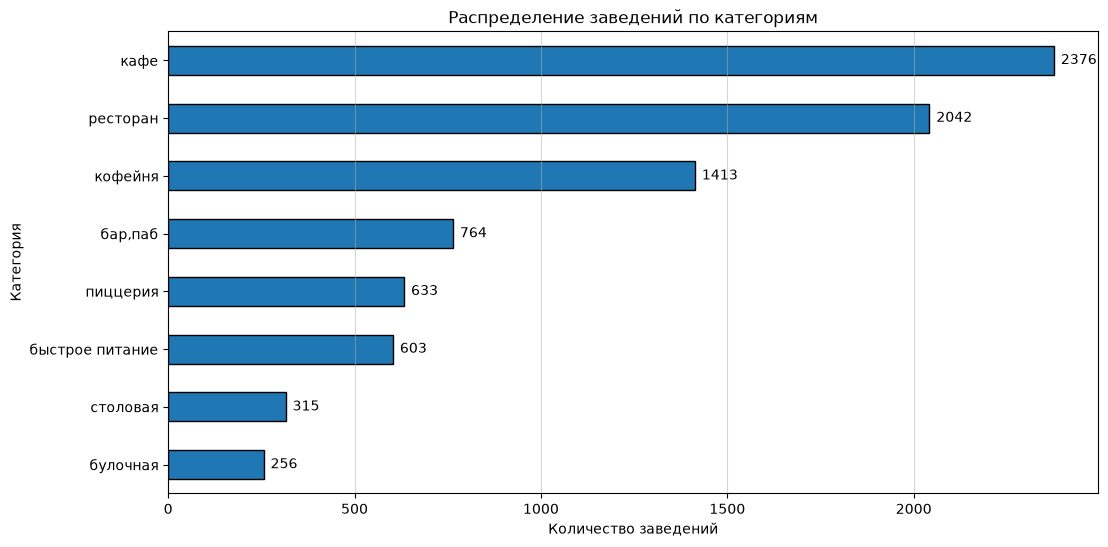

In [26]:
# Сгруппируем данные, чтобы посчитать количество заведений в каждой категории, и отсортируем по возрастанию:
count_in_category = rest_cleaned.groupby('category')['id'].agg('count').sort_values(ascending = True)

# Посчитаем относительное количество заведений по категориям и выведем их:
share_in_category = (rest_cleaned['category'].value_counts(normalize = True) * 100).round(2)
print('Относительное количество заведений по категориям')
print(share_in_category)

# Построим линейчатую диаграмму на основе наших сгруппированных данных:
count_in_category_barh = count_in_category.plot.barh(title = 'Распределение заведений по категориям',
                                                     xlabel = 'Количество заведений',
                                                     ylabel = 'Категория',
                                                     edgecolor = 'black',
                                                     figsize = (12, 6))

# Создадим функцию, которая будем в дальнейшем использовать для формирования подписей:
def add_bar_labels(ax, is_horizontal=True):
    """
    Функция добавляет подписи значений ко всем столбцам графика.
    
    Параметры:
    ax: Объект, на котором построен график.
    is_horizontal (bool): True для горизонтальных столбцов (barh), 
                          False для вертикальных (bar).
    """
    for container in ax.containers:
        for bar in container:
            if is_horizontal:
                value = bar.get_width()
                xy = (value, bar.get_y() + bar.get_height() / 2)
                xytext = (5, 0)
                ha, va = 'left', 'center'
            else:
                value = bar.get_height()
                xy = (bar.get_x() + bar.get_width() / 2, value)
                xytext = (0, 5)
                ha, va = 'center', 'bottom'
                
            # Если число целое (например, 15.0), убираем точку и выводим как 15:
            if value % 1 == 0:
                label = f'{int(value)}'
            # Если число дробное (например, 15.345), округляем ровно до 2 знаков: 15.35:
            else:
                label = f'{value:.2f}'
                
            ax.annotate(label,
                        xy = xy,
                        xytext = xytext,
                        textcoords = 'offset points',
                        ha = ha, va = va)

# Подпишем значения рядом с нашими столбцами, используя функцию:
add_bar_labels(count_in_category_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси Х:
plt.grid(axis='x', alpha=0.5)

# Выведем наш график:
plt.show()

**Итог:** Наблюдаем, что больше всего заведений относится к категории `кафе` - 2376 заведений (28,28%).
Следом идут категории: `рестораны` - 2042 заведения (24,30%), `кофейни` - 1413 (16,82%), `бары или пабы` - 764 (9,09%), `пиццерии` - 633 (7,53%), `заведения быстрого питания` - 603 (7,18%), `столовые` - 315 (3,75%), а меньше всего `булочных` - их всего 256 (3,05%). Для наглядности данные по всем категориям представлены на графике.

[Вернуться к содержанию](#Содержание)

<a id="Распределение-заведений-по-административным-районам"></a>
### Распределение заведений по административным районам

Теперь изучим, какие административные районы Москвы присутствуют в данных, и исследуем распределение количества заведений по этим районам. Будем использовать тот же способ, что и выше:

Относительное количество заведений по районам Москвы
district
Центральный административный округ         26.68
Северный административный округ            10.69
Южный административный округ               10.62
Северо-Восточный административный округ    10.59
Западный административный округ            10.12
Восточный административный округ            9.50
Юго-Восточный административный округ        8.50
Юго-Западный административный округ         8.44
Северо-Западный административный округ      4.87
Name: proportion, dtype: float64


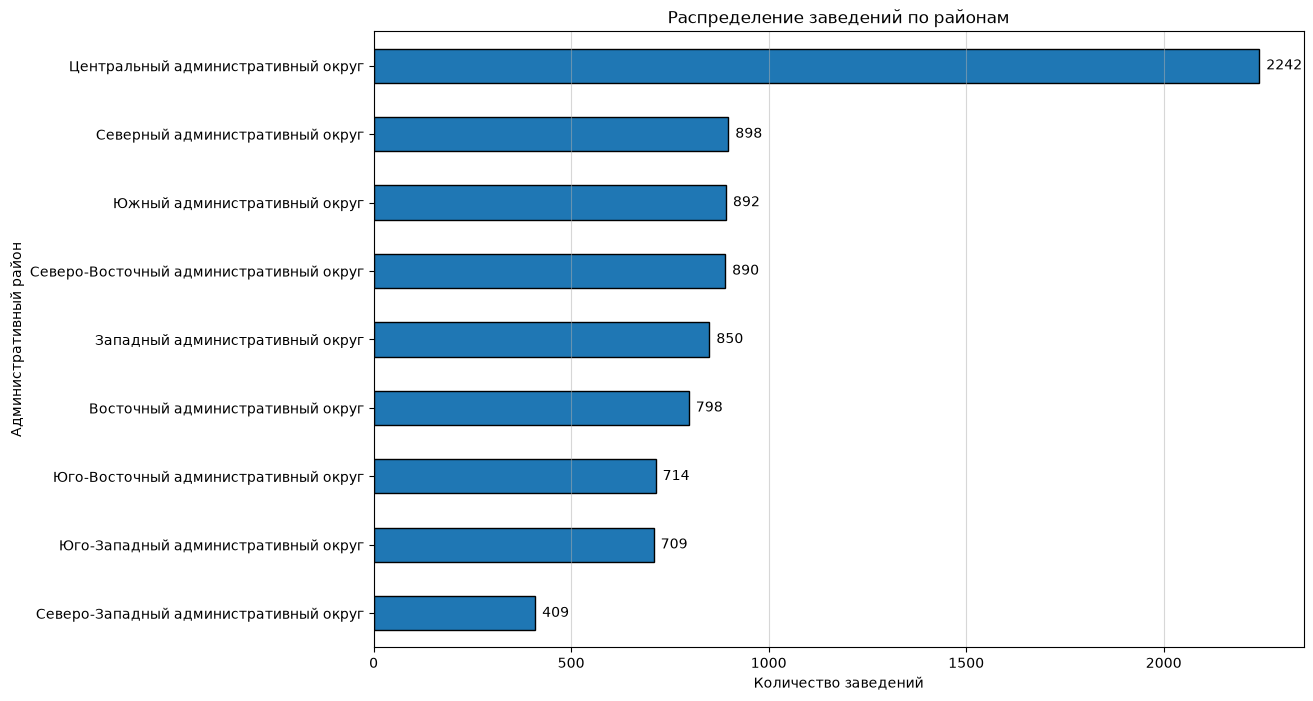

In [27]:
# Сгруппируем данные, чтобы посчитать количество заведений в каждой категории, и отсортируем по возрастанию:
count_in_district = rest_cleaned.groupby('district')['id'].agg('count').sort_values(ascending = True)

# Посчитаем относительное количество заведений по районам и выведем их:
share_in_district = (rest_cleaned['district'].value_counts(normalize = True) * 100).round(2)
print('Относительное количество заведений по районам Москвы')
print(share_in_district)

# Построим линейчатую диаграмму на основе наших сгруппированных данных:
count_in_district_barh = count_in_district.plot.barh(title = 'Распределение заведений по районам',
                                                     xlabel = 'Количество заведений',
                                                     ylabel = 'Административный район',
                                                     edgecolor = 'black',
                                                     figsize = (12, 8))

# Дополнительно подпишем значения рядом с нашими столбцами:
add_bar_labels(count_in_district_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis='x', alpha=0.5)

# Выведем наш график:
plt.show()

**Итог:** Наблюдаем, что подавляющее число заведений размещено в `Центральном административном округе` - 2242 заведения (26,68%). Следующее по численности значение в `Северном административном округе` - 898 заведений (10,69%). В остальных административных округах количество заведений находится в диапозоне от 700 до 900 заведений (от 8,4 до 10,7%). А меньше всего в `Северо-Западном` - их всего 409 (4,87%). Данные по всем категориям представлены на графике.

Объяснить такую плотность объектов общественного питания в Центральном административном округе несложно. Район является главным историческим, политическим, деловым и культурным местом Москвы: здесь и Кремль, и Дом Правительства, и Красная площадь, и "Москва-Сити", и Большой театр, и Третьяковская галерея, и много чего ещё интересного.

[Вернуться к содержанию](#Содержание)

<a id="Распределение-заведений-по-категориям-в-Центральном-административном-округе"></a>
### Распределение заведений по категориям в Центральном административном округе

Давайте отдельно рассмотрим распределение заведений каждой категории в данном районе Москвы:

Относительное количество заведений по категориям в ЦАО
category
ресторан           29.88
кафе               20.70
кофейня            19.09
бар,паб            16.24
пиццерия            5.04
быстрое питание     3.88
столовая            2.94
булочная            2.23
Name: proportion, dtype: float64


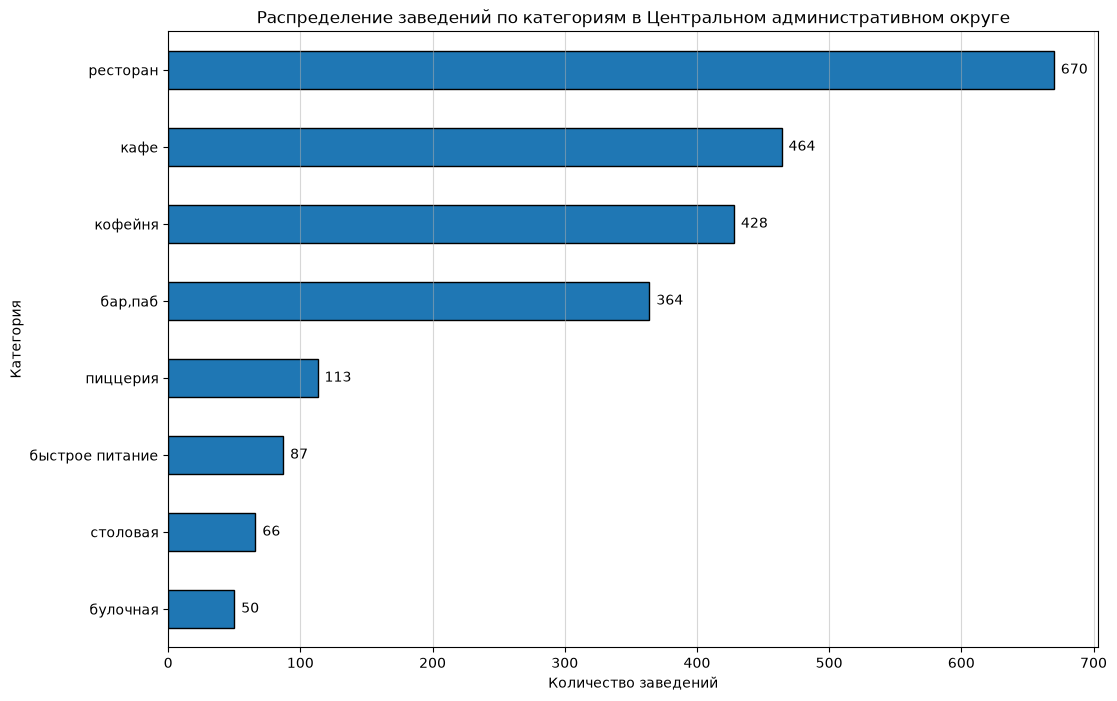

In [28]:
# Отбираем только те данные, где нужный нам район Москвы:
central_rest_cleaned = rest_cleaned[rest_cleaned['district'] == 'Центральный административный округ']

# Сгруппируем данные, чтобы посчитать количество заведений в каждой категории, и отсортируем по возрастанию:
count_in_central = central_rest_cleaned.groupby('category')['id'].agg('count').sort_values(ascending = True)

# Посчитаем относительное количество заведений по категориям и выведем их:
share_in_central = (central_rest_cleaned['category'].value_counts(normalize = True) * 100).round(2)
print('Относительное количество заведений по категориям в ЦАО')
print(share_in_central)

# Построим линейчатую диаграмму на основе наших сгруппированных данных:
count_in_central_barh = count_in_central.plot.barh(title = 'Распределение заведений по категориям в Центральном административном округе',
                                                   xlabel = 'Количество заведений',
                                                   ylabel = 'Категория',
                                                   edgecolor = 'black',      
                                                   figsize = (12, 8))

# Дополнительно подпишем значения рядом с нашими столбцами:
add_bar_labels(count_in_central_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis='x', alpha=0.5)

# Выведем наш график:
plt.show()

**Итог:** Наблюдаем большое количество ресторанов - 670 единиц (29,88%). Следом идут: `кафе` - 464 заведения (20,70%), `кофейни` - 428 (19,09%), `бары и пабы` - 364 (16,24%), `пиццерии` - 113 (5,04%), `заведения быстрого питания` - 87 (3,88%), `столовые` - 66 (2,94%), `булочные` - 50 (2,23%).

Опять же несложно объяснить такое количество ресторанов - здесь большой поток платежеспособной аудитории, которая приезжает сюда работать, отдыхать и тратить деньги.

[Вернуться к содержанию](#Содержание)

<a id="Соотношение-сетевых-и-несетевых-заведений-в-целом-и-в-разрезе-категорий"></a>
### Соотношение сетевых и несетевых заведений в целом и в разрезе категорий

Теперь изучим соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. И после ответим на вопросы:
1. Каких заведений больше — сетевых или несетевых?
2. Какие категории заведений чаще являются сетевыми? 

Для того, чтобы ответить на первый вопрос, построим круговую диаграмму: 

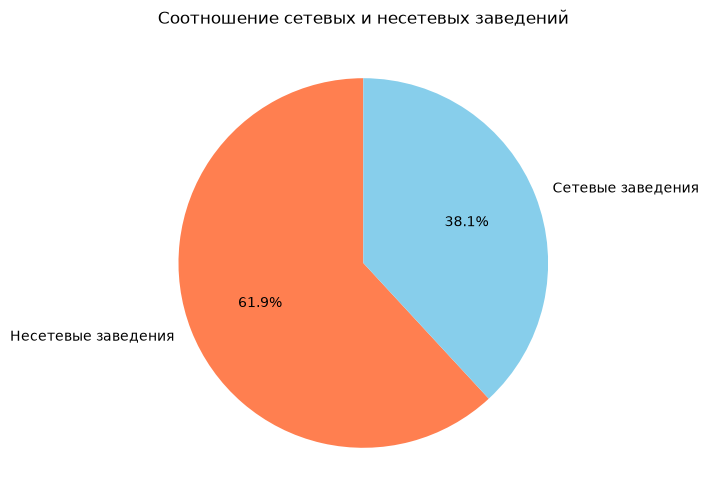

In [29]:
# Посчитаем абсолютное количество сетевых и несетевых заведений:
chain_counts = rest_cleaned['chain'].value_counts()

# Построим круговую диаграмму:
chain_counts.plot(kind = 'pie',
                  ylabel = '',
                  autopct = '%1.1f%%', # Этот параметр переведет данные в проценты
                  startangle = 90,
                  colors = ['coral', 'skyblue'],
                  labels = ['Несетевые заведения', 'Сетевые заведения'],
                  title = 'Соотношение сетевых и несетевых заведений',
                  figsize=(6, 6))

# Выведем наш график:
plt.show()

Мы видим, что `несетевых заведений` (61,9%) в нашем датасете заметно больше, чем `сетевых` (38,1%)

Теперь давайте ответим на второй вопрос и узнаем, какие категории заведений чаще являются сетевыми. Для этого построим столбчатую диаграмму с накоплением:

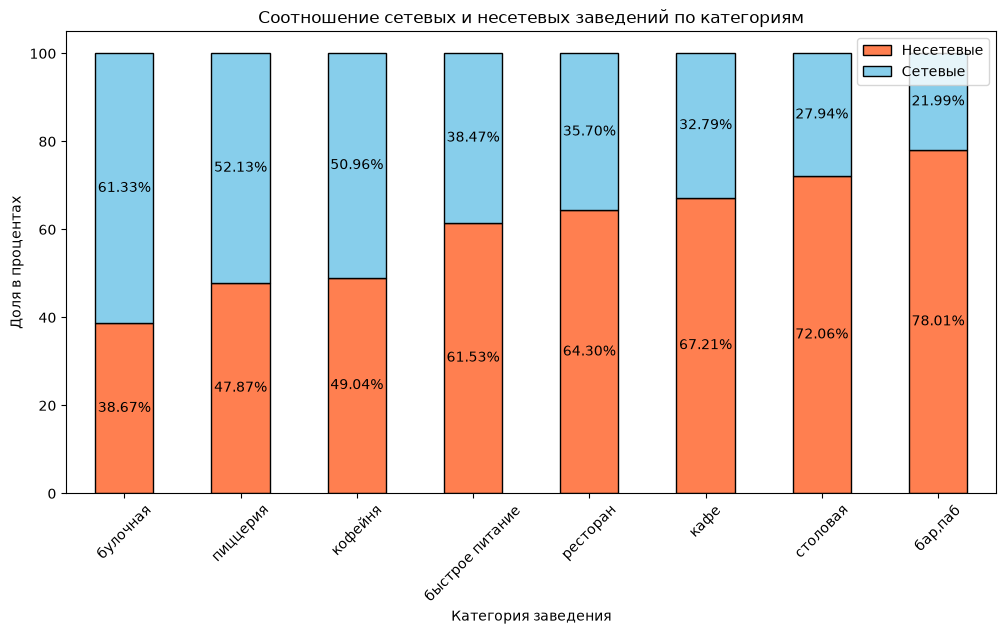

In [30]:
# Сруппируем данные и относительное количество, затем переведем в проценты:
category_chain = rest_cleaned.groupby('category')['chain'].value_counts(normalize = True).unstack()
category_chain = category_chain * 100

# Сортируем по убыванию доли сетевых заведений:
category_chain = category_chain.sort_values(by = 1, ascending = False)

# Создаем столбчатую диаграмму с накоплением (используем параметр stacked):
category_chain_bar = category_chain.plot(kind = 'bar',
                                         stacked = True,
                                         color = ['coral', 'skyblue'],
                                         edgecolor = 'black',
                                         title = 'Соотношение сетевых и несетевых заведений по категориям',
                                         xlabel= 'Категория заведения',
                                         ylabel = 'Доля в процентах',
                                         rot = 45,
                                         figsize = (12, 6))

# Дополнительно подпишем значения рядом с нашими столбцами:
for container in category_chain_bar.containers:
    for bar in container:
        value = bar.get_height()
        
        # Считаем центр столбцов, чтобы разместить там значения:
        x_pos = bar.get_x() + bar.get_width() / 2
        y_pos = bar.get_y() + value / 2
            
        # Наносим подпись в центре столбцов:
        label = f'{value:.2f}%'
        category_chain_bar.annotate(label,
                                    xy = (x_pos, y_pos),
                                    xytext = (0, 0),
                                    textcoords = 'offset points',
                                    ha = 'center', va = 'center')

# Подпишем легенду:
plt.legend(['Несетевые', 'Сетевые'])

# Выведем наш график:
plt.show()

**Итог:** мы наблюдаем, что `несетевых заведений` (61,9%) в нашем датасете заметно больше, чем `сетевых` (38,1%). Чаще всего сетевыми бывают следующие категории:
1. `булочная` - 61,33% сетевых против 38,67% несетевых;
2. `пиццерия` — 52,13% сетевых против 47,87% несетевых;
3. `кофейня` — 50,96% сетевых против 49,04% несетевых;
4. `быстрое питание` — 38,47% сетевых против 61,53% несетевых;
5. `ресторан` — 35,70% сетевых против 64,30% несетевых;
6. `кафе` — 32,79% сетевых против 67,21% несетевых;
7. `столовая` — 27,94% сетевых против 72,06% несетевых;
8. `бар, паб` — 21,99% сетевых против 78,01% несетевых.

[Вернуться к содержанию](#Содержание)

<a id="Распределение-количества-посадочных-мест-в-заведениях-по-категориям"></a>
### Распределение количества посадочных мест в заведениях по категориям

Исследуем количество посадочных мест в заведениях, ответив на вопросы:
1. Встречаются ли в данных аномальные значения или выбросы?
2. Если да, то с чем они могут быть связаны?

Далее приведем для каждой категории заведений наиболее типичное для него количество посадочных мест.

Чтобы ответить на первый вопрос, построим диаграмму размаха:

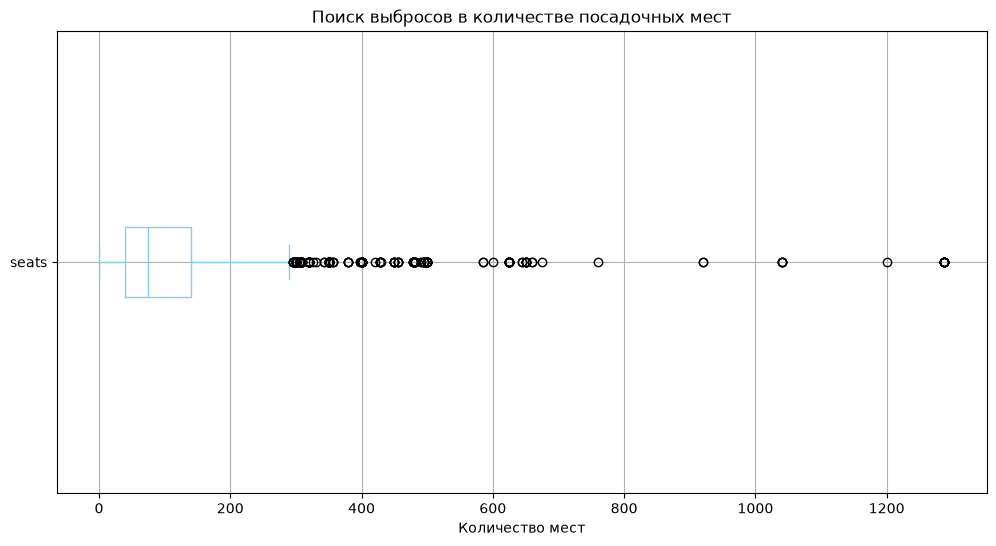

In [31]:
# Построим диаграмму размаха:
seats_boxplot = rest_cleaned.boxplot(column = 'seats',
                                     vert = False,
                                     color = 'skyblue',
                                     figsize=(12, 6))

# Добавим заголовок и подпишем ось Х:
seats_boxplot.set_title('Поиск выбросов в количестве посадочных мест')
seats_boxplot.set_xlabel('Количество мест')

# Выведем наш график:
plt.show()

Давайте рассмотрим размах подробнее:

In [32]:
rest_cleaned['seats'].describe()

count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

Так мы видим следующее:
- Всего у нас 4792 отметки о количестве мест;
- В среднем 108 посадочных мест в заведениях;
- Стандартное отклонение - примерно 123;
- Минимальное значение мест - 0, что не является аномальным значением, ведь некоторые заведения работают исключительно навынос либо на доставку;
- Первый квартиль - 40;
- Второй квартиль или медиана - 75;
- Третий квартиль - 140;
- Максимальное значение мест - 1288, что является аномальным.

Мы видим, что третий квартиль и максимальное значение значительно рознятся. В рамках исследования будем считать, что выбросом можно считать значения, выше 99-го процентиля. Посчитаем его:

In [33]:
# Посчитаем 99-й процентиль и сделаем его целым числом:
outliers = rest_cleaned['seats'].quantile(0.99).astype('int')

# Выведем результат в виде целого числа:
print(f'99-й процентиль равняется {outliers} посадочным местам')

99-й процентиль равняется 625 посадочным местам


Значения, выше 625 мест, будем считать выбросами. Почему мы взяли 99-й процентиль: если бы мы взяли, например, 95-й, мы могли бы ошибочно считать выбросом адекватное количество посадочных мест в банкетных залах (для них 500 мест является стандартом), которые принадлежат ресторанам. То же касается и столовых, к примеру, которые рассчитаны на большой поток людей, т.е. имеют большое количество посадочных мест.

Давайте посчитаем количество аномальных значений:

In [34]:
outliers_rest_cleaned = rest_cleaned.loc[rest_cleaned['seats'] > outliers]
len(outliers_rest_cleaned)

30

Наблюдаем 30 значений-выбросов. Их наличие в нашем датасете может быть связано, например, с ошибочным вводом данных на сервисах Яндекса. Т.е. пользователь или владелец опечатался или вписал другое значение (площадь, например). Или, например, заведение располагается рядом с другими заведениями на фуд-корте и в данное поле было записано общее количество посадочных мест.

Теперь давайте приведем для каждой категории заведений наиболее типичное для него количество посадочных мест. Наиболее типичное количество определим через медиану, так как она более устоичива к аномальным значениям, в отличие от среднего арифметического значения. Приступим:

Типичное (медианное) количество мест
category
булочная           50.0
пиццерия           55.0
кафе               60.0
быстрое питание    65.0
столовая           75.5
кофейня            80.0
бар,паб            82.0
ресторан           86.0
Name: seats, dtype: float64


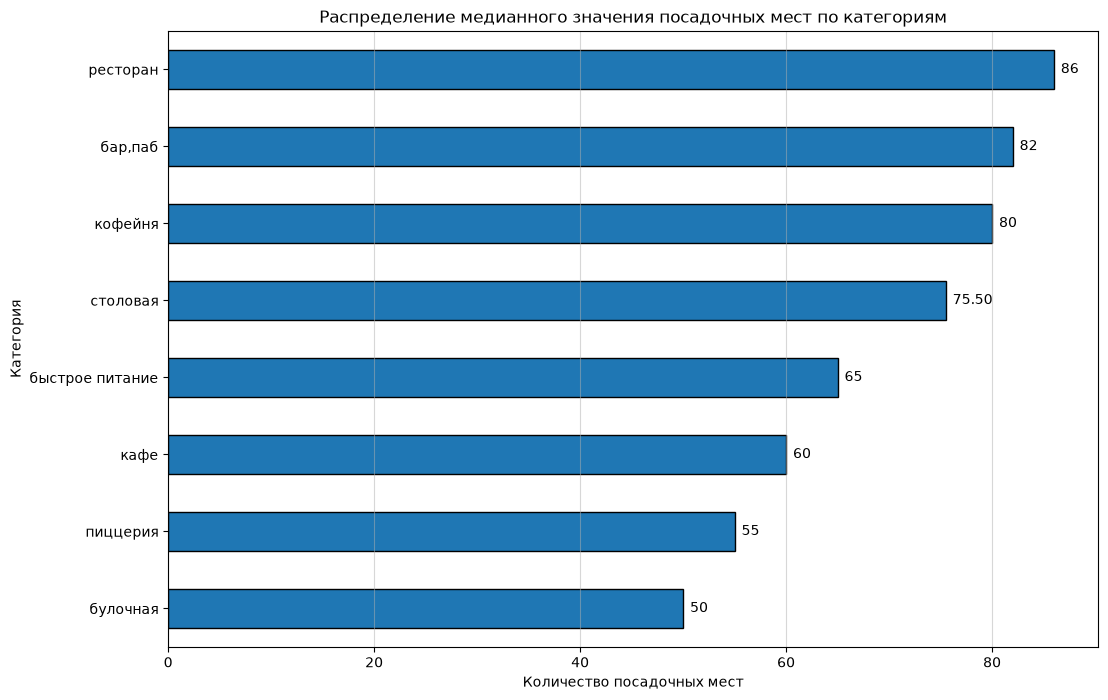

In [35]:
# Посчитаем медиану для каждой категории и отсортируем:
typical_seats = rest_cleaned.groupby('category')['seats'].median()
typical_seats = typical_seats.sort_values(ascending = True)

# Выведем полученные значения:
print('Типичное (медианное) количество мест')
print(typical_seats)

# Построим линейчатую диаграмму на основе наших сгруппированных данных:
typical_seats_barh = typical_seats.plot.barh(title = 'Распределение медианного значения посадочных мест по категориям',
                                             xlabel = 'Количество посадочных мест',
                                             ylabel = 'Категория',
                                             edgecolor = 'black',
                                             figsize = (12, 8))

# Дополнительно подпишем значения рядом с нашими столбцами:
add_bar_labels(typical_seats_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis='x', alpha=0.5)

# Выведем наш график:
plt.show()

Больше всего посадочных мест расположено в `ресторанах` (медиана — 86 мест) и `барах/пабах` (82 места). Интересно, что мы имеем высокие показатели для `кофеен` (80 мест) и `булочных` (50 мест). Обычно в заведениях такого типа немного мест, где-то 15-30. Такие высокие значения свидетельствую о том, что в нашу выборку попали крупные заведения либо при заполнении карточек на сервисах Яндекса заведения других категорий (кафе, например) были ошибочно отнесены к кофейням и булочным.

Далее типичное количество посадочных мест распределено вот так:
- `столовая` - 75,5 (75-76). Число дробное, потому что в выборке четное количество столовых, из которых библиотека `pandas` не может определить одно центральное значение, так как их два, поэтому он считает среднее арифметическое между ними;
- `заведения быстрого питания` - 65;
- `кафе` - 60;
- `пиццерия` - 55.

**Итог:** В нашем датасете встречаются аномальные значения. Мы посчитали, что все значения выше нашего 99-го процентиля - 625 посадочных мест - будут для нас выбросами. Всего мы насчитали 30 таких значений.

Появление выбросов в данных мы решили объяснить ошибочным вводом данных на сервисах Яндекса.

Также перед нами стояла задача определить типичное количество посадочных мест в зависимости от категории заведения. Под типичным количеством мы приняли считать медианное значение, так как такой способ минимизирует влияние выбросов на итоговое значение. Получили следующее распределение:
1. `ресторан` - 86;
2. `бар,паб` - 82;
3. `кофейня` - 80;
4. `столовая` - 75-76;
5. `заведения быстрого питания` - 65;
6. `кафе` - 60;
7. `пиццерия` - 55;
8. `булочная` - 50.

[Вернуться к содержанию](#Содержание)

<a id="Распределение-средних-рейтингов-по-категориям-заведений"></a>
### Распределение средних рейтингов по категориям заведений

Теперь исследуем рейтинг заведений. Изучим распределение средних рейтингов по категориям заведений:

Средние рейтинги по категориям
category
быстрое питание    4.05
кафе               4.12
столовая           4.21
булочная           4.27
кофейня            4.28
ресторан           4.29
пиццерия           4.30
бар,паб            4.39
Name: rating, dtype: float64


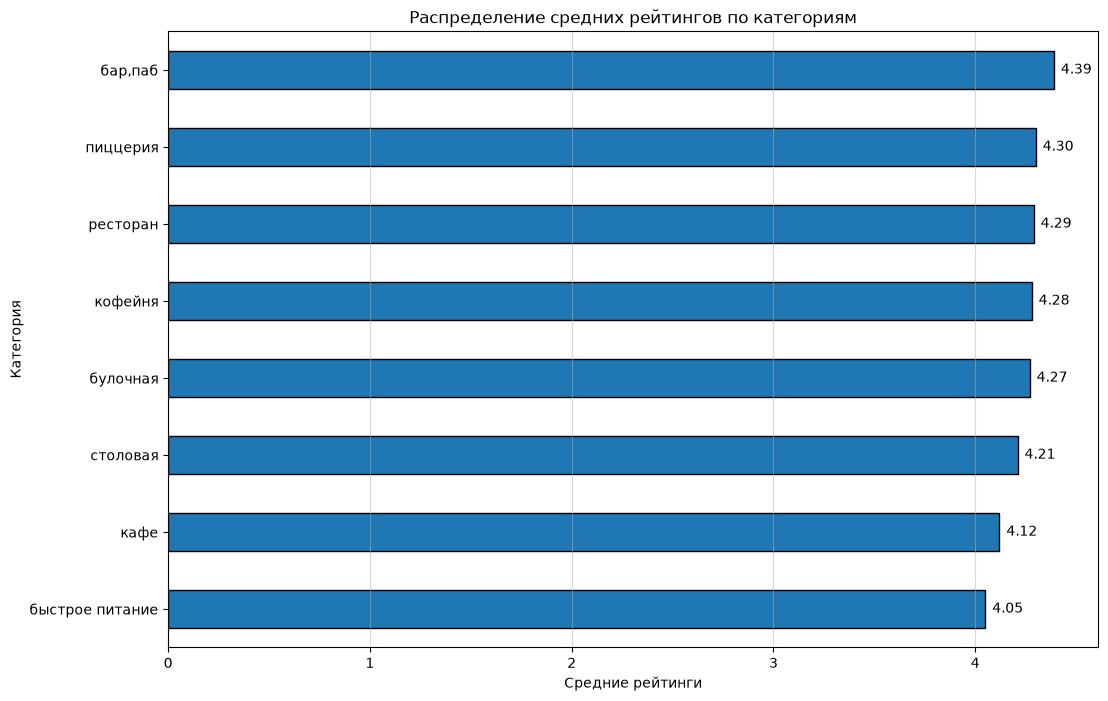

In [36]:
# Посчитаем средний рейтинг для каждой категории, округлим до двух знаков и отсортируем:
avg_category_rating = rest_cleaned.groupby('category')['rating'].mean().round(2)
avg_category_rating = avg_category_rating.sort_values(ascending = True)

# Выведем полученные значения:
print('Средние рейтинги по категориям')
print(avg_category_rating)

# Построим линейчатую диаграмму на основе наших сгруппированных данных:
avg_category_rating_barh = avg_category_rating.plot.barh(title = 'Распределение средних рейтингов по категориям',
                                                         xlabel = 'Средние рейтинги',
                                                         ylabel = 'Категория',
                                                         edgecolor = 'black',
                                                         figsize = (12, 8))

# Дополнительно подпишем значения рядом с нашими столбцами:
add_bar_labels(avg_category_rating_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis='x', alpha=0.5)

# Выведем наш график:
plt.show()

**Итог:** Наблюдаем, что значения средних рейтингов не сильно разнятся в зависимости от категории. Результат распредения такой:
1. `бар/паб` - 4,39;
2. `пиццерия` - 4,30;
3. `ресторан` - 4,29;
4. `кофейня` - 4,28;
5. `булочная` - 4,27;
6. `столовая` - 4,21;
7. `кафе` - 4,12;
8. `заведения быстрого питания` - 4,05.

Но давайте ещё проверим зависимость рейтинга от других данных.

[Вернуться к содержанию](#Содержание)

<a id="Корреляция-рейтинга-заведений-с-другими-данными"></a>
### Корреляция рейтинга заведений с другими данными

Изучим, с какими данными показывают самую сильную корреляцию рейтинги заведений. Будем проверять корреляции рейтинга заведения с такими данными как: категория заведения, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным.

Для этого построим и визуализируем матрицу в виде тепловой карты:

interval columns not set, guessing: ['chain', 'seats', 'rating']


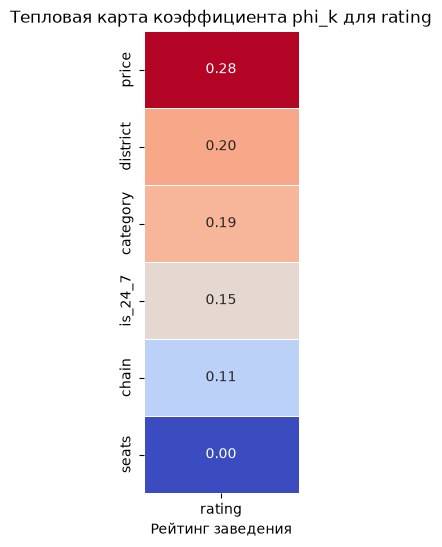

In [37]:
# Вычисляем корреляционную матрицу с использованием phi_k:
corr_columns = ['category',
                'district',
                'chain',
                'seats',
                'price',
                'is_24_7',
                'rating']
correlation_matrix = rest_cleaned[corr_columns].phik_matrix()

# Строим тепловую карту:
plt.figure(figsize=(2, 6))

# Сохраняем матрицу корреляции rating с другими данными:
data_heatmap = correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)
sns.heatmap(data_heatmap,
            annot = True,
            fmt = '.2f',
            cmap = 'coolwarm',
            linewidths = 0.5,
            cbar = False)

# Добавляем заголовок и подпись по оси Х:
plt.title('Тепловая карта коэффициента phi_k для rating')
plt.xlabel('Рейтинг заведения')

# Выводим график:
plt.show()

Наблюдаем, что сильнейшую взаимосвязь рейтинг имеет с ценовой категорией - коэффициент `phi_k` равняется 0,28. Следующая по силе взаимосвязь с расположением заведения - 0,20; затем с категорией заведения - 0,19; потом с признаком "круглосуточности" заведения - 0,15; далее с тем, является заведение сетевым или нет - 0,11. Нулевая взаимосвязь рейтинга с количеством посадочных мест.

Приверим сильнейшую взаимосвязь:

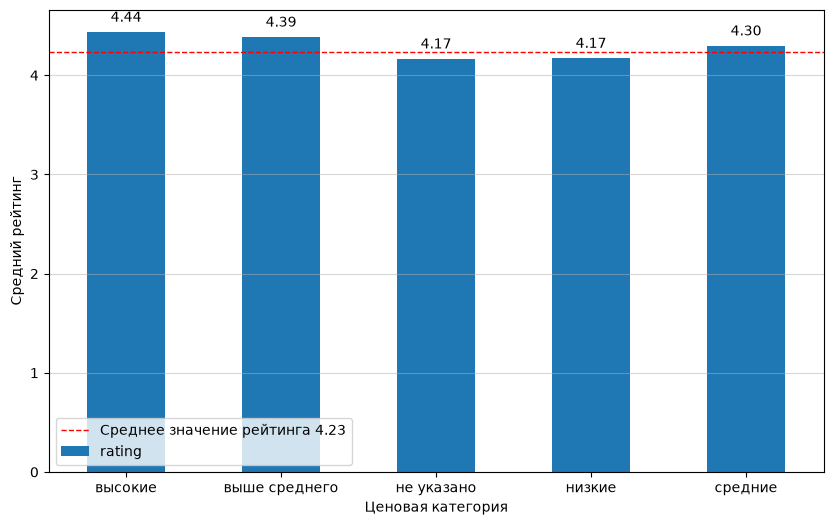

In [38]:
# Строим столбчатую диаграмму:
price_rating = rest_cleaned.groupby('price')['rating'].mean()
rating_price_bar = price_rating.plot(kind = 'bar',
                                     legend = True,
                                     ylabel = 'Средний рейтинг',
                                     xlabel = 'Ценовая категория',
                                     figsize = (10, 6),
                                     rot = 0)

# Рассчитываем среднее значение по рейтингу:
mean_rating = rest_cleaned['rating'].mean()

# Нанесем на график линию со средним значением по рейтингу:
plt.axhline(mean_rating,
            color = 'red',
            linestyle = '--',
            linewidth = 1,
            label = f'Среднее значение рейтинга {round(mean_rating,4)}')

# Дополнительно подпишем значения рядом с нашими столбцами:
add_bar_labels(rating_price_bar, is_horizontal = False)

# Сделаем полупрозрачную сетку по оси Y:
plt.grid(axis='y', alpha=0.5)
plt.legend()

# Выводим график:
plt.show()

Наблюдаем, что с ростом ценовой категории увеличивается средний рейтинг заведения: самый высокий рейтинг имеют заведения с высокими ценами (4,44) и ценами выше среднего (4,39). Они заметно превышают линию среднего рейтинга по всему датасету (4,23). Заведения со средними ценами имеют рейтинг 4,30, также превышают линию среднего рейтинга, однако не так сильно.

Самый низкий средний балл зафиксирован в категориях низких цен (4,17) и значения «не указано» (4,17). Они находятся  под линией среднего рейтинга.

**Итог:** Была установлена сила взаимосвязи рейтинга с другими данными:
1. Сильнейшая взаимосвязь у рейтинга с ценовой категорией (коэффициент `phi_k` равняется 0,28);
2. Следующая по силе взаимосвязь с расположением заведения - 0,20;
3. Затем с категорией заведения - 0,19;
4. Потом с признаком "круглосуточности" заведения - 0,15;
5. Далее с тем, является заведение сетевым или нет - 0,11.
6. Нулевая взаимосвязь рейтинга с количеством посадочных мест - 0,00.

Также была проверена сильнейшая взаимосвязь: с ростом ценовой категории увеличивается средний рейтинг заведения. Мы получили следующие значения:
1. Заведения с высокими ценами - средний рейтинг равняется 4,44 (выше среднего по датасету, который равняется 4,23);
2. Заведения с ценами выше среднего - средний рейтинг равняется 4,39 (выше среднего по датасету);
3. Заведения со средними ценами - средний рейтинг равняется 4,30 (выше среднего по датасету);
4. Заведения с низкими ценами и те, где цены не указаны, - средний рейтинг 4,17 (ниже среднего по датасету).

[Вернуться к содержанию](#Содержание)

<a id="Определение-топ-15-популярных-сетей-в-Москве"></a>
### Определение топ-15 популярных сетей в Москве

Теперь сгруппируем данные по названиям заведений и найдем топ-15 популярных сетей в Москве. Для них посчитаем значения среднего рейтинга.

In [39]:
# Создаем топ заведений по количеству заведений этой сети в регионе (сортируем от большего к меньшему):
top_name = rest_cleaned.groupby('name').agg({'address': 'count', 'rating': 'mean', 'category': 'first'})
top_name = top_name.sort_values(by = 'address', ascending = False).reset_index()

# Переименовываем столбец address для наглядности:
top_name = top_name.rename(columns = {'address': 'count'})

# Округляем значения среднего рейтинга:
top_name['rating'] = top_name['rating'].round(2)

# Отбираем первые 15 значений:
top_15 = top_name.head(15)
top_15

,name,count,rating,category
0,кафе,188,3.88,кафе
1,шоколадница,120,4.18,кофейня
2,домино'с пицца,77,4.17,пиццерия
3,додо пицца,74,4.29,пиццерия
4,one price coffee,72,4.07,кофейня
5,яндекс лавка,69,3.87,ресторан
6,cofix,65,4.08,кофейня
7,prime,50,4.12,ресторан
8,хинкальная,44,4.32,быстрое питание
9,шаурма,43,3.91,быстрое питание


Видим, что в топ попали заведения с названием "кафе" и "ресторан". Вероятно, в общем датасете будут присутствовать ещё и "пиццерия", "булочная" и т.д. Связано это может быть с рядом причин (например, с ошибкой выгрузки данных или ошибкой на сервисах Яндекса). Однако, по нашему мнению, это вероятнее всего связано с тем, что в Москве много старых заведений, которые не имеют названия. При группировке они объединились в условную сеть. Чтобы это устранить, давайте исключим из названий заведений все названия категорий, тем самым оставив названия действительных сетей.

In [40]:
# Исключаем из названий заведений названия категорий:
new_top_name = top_name[~top_name['name'].isin(rest_cleaned['category'].unique())]

# Превращаем столбец name в индекс:
new_top_name = new_top_name.set_index('name')

# Снова отбираем первые 15 значений:
new_top_15 = new_top_name.head(15)
new_top_15

,count,rating,category
name,,,
шоколадница,120,4.18,кофейня
домино'с пицца,77,4.17,пиццерия
додо пицца,74,4.29,пиццерия
one price coffee,72,4.07,кофейня
яндекс лавка,69,3.87,ресторан
cofix,65,4.08,кофейня
prime,50,4.12,ресторан
хинкальная,44,4.32,быстрое питание
шаурма,43,3.91,быстрое питание


Сформируем линейчатый график по количеству заведений в сети:

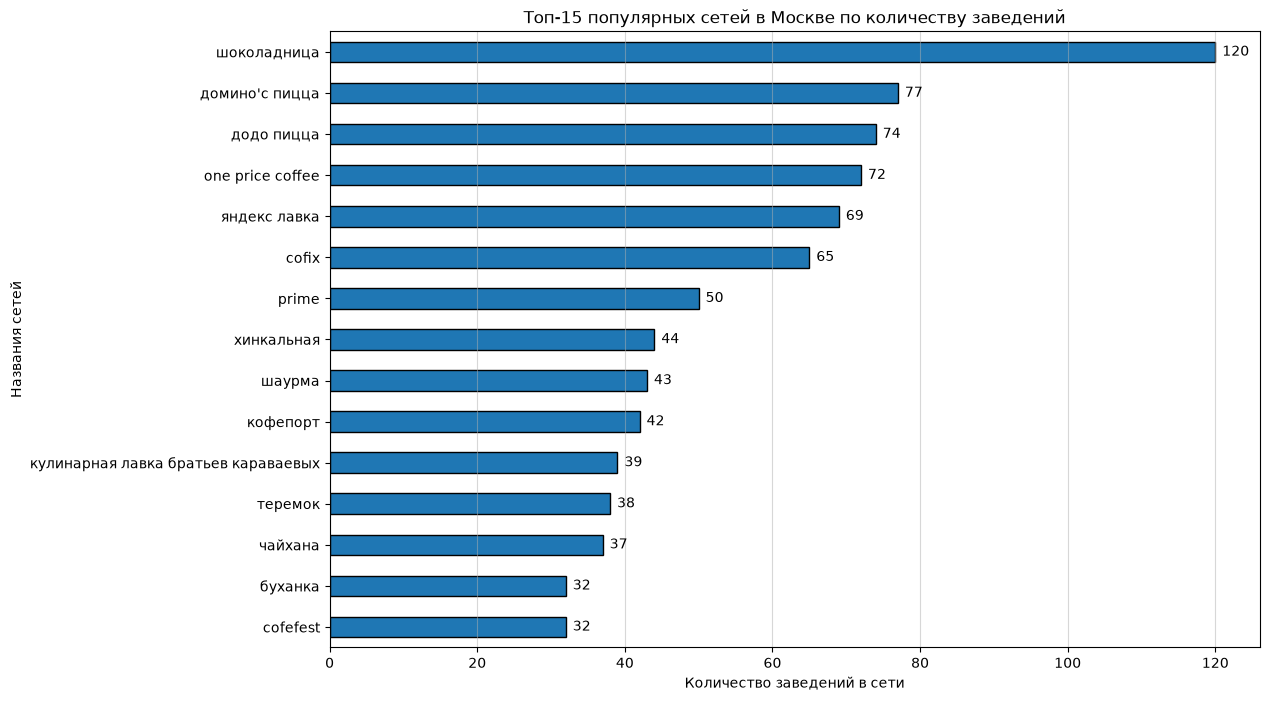

In [41]:
# Сортируем данные для графика:
new_top_15 = new_top_15.sort_values(by = 'count', ascending = True)

# Построим линейчатую диаграмму на основе наших сгруппированных данных:
top_15_count_barh = new_top_15.plot.barh(title = 'Топ-15 популярных сетей в Москве по количеству заведений',
                                         y = 'count',
                                         xlabel = 'Количество заведений в сети',
                                         ylabel = 'Названия сетей',
                                         edgecolor = 'black',
                                         figsize = (12, 8),
                                         legend = False)

# Дополнительно подпишем значения рядом с нашими столбцами:
add_bar_labels(top_15_count_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis='x', alpha=0.5)

# Выведем наш график:
plt.show()

Теперь построим тот же график, но отметим средние значения рейтинга по сетям:

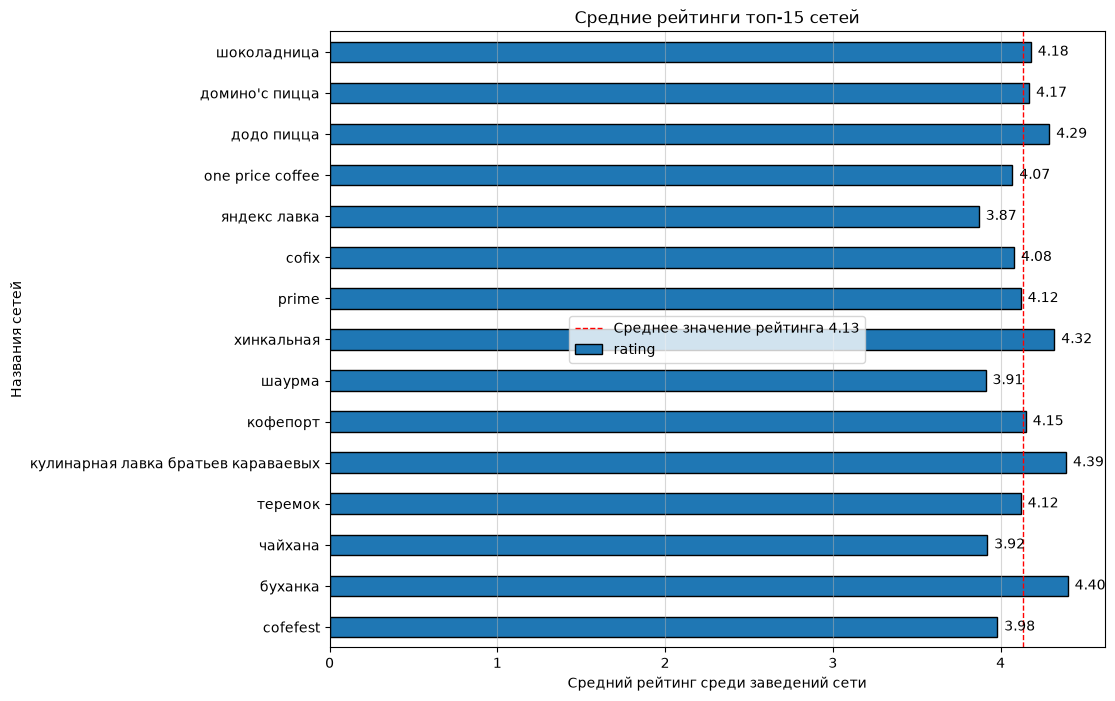

In [42]:
# Построим линейчатую диаграмму на основе наших сгруппированных данных:
top_15_rating_barh = new_top_15.plot.barh(title = 'Средние рейтинги топ‑15 сетей',
                                          y = 'rating',
                                          xlabel = 'Средний рейтинг среди заведений сети',
                                          ylabel = 'Названия сетей',
                                          edgecolor = 'black',
                                          figsize = (10, 8),
                                          legend = False)

# Рассчитываем среднее значение по рейтингу:
mean_rating_in_top_15 = new_top_15['rating'].mean()

# Нанесем на график линию со средним значением:
plt.axvline(mean_rating_in_top_15,
            color = 'red',
            linestyle = '--',
            linewidth = 1,
            label = f'Среднее значение рейтинга {round(mean_rating_in_top_15, 2)}')

# Дополнительно подпишем значения рядом с нашими столбцами и добавим легенду:
add_bar_labels(top_15_rating_barh, is_horizontal = True)
top_15_rating_barh.legend(loc = 'center')

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis='x', alpha=0.5)

# Выведем наш график:
plt.show()

Давайте узнаем, к какой категориям относятся заведения из нашего топа. Построим для этого круговую диаграмму с соотношением категорий:

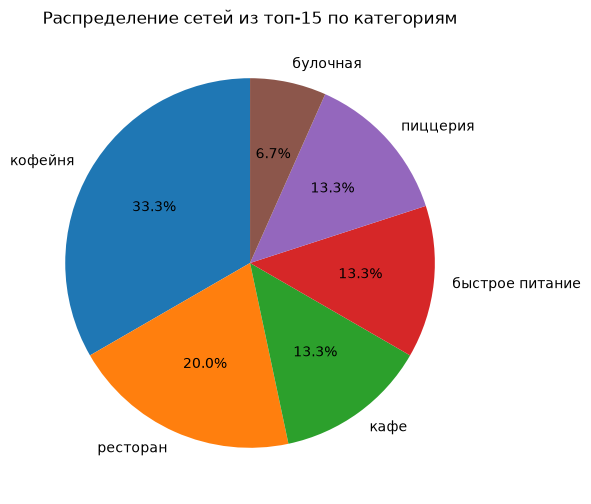

In [43]:
# Посчитаем абсолютное количество заведений из топ-15 по категориям:
category_pie = new_top_15['category'].value_counts()

# Построим круговую диаграмму:
category_pie.plot(kind = 'pie',
                  ylabel = '',
                  autopct = '%1.1f%%',
                  startangle = 90,
                  title = 'Распределение сетей из топ-15 по категориям',
                  figsize=(6, 6))

# Выведем наш график:
plt.show()

**Итог:** Мы получили следующий топ-15 популярных сетей в Москве (под популярностью мы имеем в виду количество заведений сети):
1. `шоколадница` — 120 заведений, средняя оценка 4,18;
2. `домино'с пицца` — 77 заведений, средняя оценка 4,17;
3. `додо пицца` — 74 заведения, средняя оценка 4,29;
4. `one price coffee` — 72 заведения, средняя оценка 4,07;
5. `яндекс лавка` — 69 заведений, средняя оценка 3,87;
6. `cofix` — 65 заведений, средняя оценка 4,08;
7. `prime` — 50 заведений, средняя оценка 4,12;
8. `хинкальная` — 44 заведения, средняя оценка 4,32;
9. `шаурма` — 43 заведения, средняя оценка 3,91;
10. `кофепорт` — 42 заведения, средняя оценка 4,15;
11. `кулинарная лавка братьев караваевых` — 39 заведений, средняя оценка 4,39;
12. `теремок` — 38 заведений, средняя оценка 4,12;
13. `чайхана` — 37 заведений, средняя оценка 3,92;
14. `cofefest` — 32 заведения, средняя оценка 3,98;
15. `буханка` — 32 заведения, средняя оценка 4,40.

В рамках этого топа мы определили доли категорий заведений:
- `кофейни` - 33,3%;
- `ресторан` - 20,0%;
- `кафе` - 13,3%;
- `заведения быстрого питания` - 13,3%;
- `пиццерии` - 13,3%;
- `булочные` - 6,7%.

[Вернуться к содержанию](#Содержание)

<a id="Анализ-вариаций-среднего-чека-в-зависимости-от-расположения"></a>
### Анализ вариаций среднего чека в зависимости от расположения

Наконец, изучим вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируем цены в центральном административном округе и других. Изучим, как удалённость от центра влияет на цены в заведениях.

Чтобы изучить этот вопрос, построим ящик с усами по каждому округу. При формировании графика установим лимит по 99-му процентилю, чтобы убрать аномально высокие значения, которые испортят визуальльное восприятие графика:

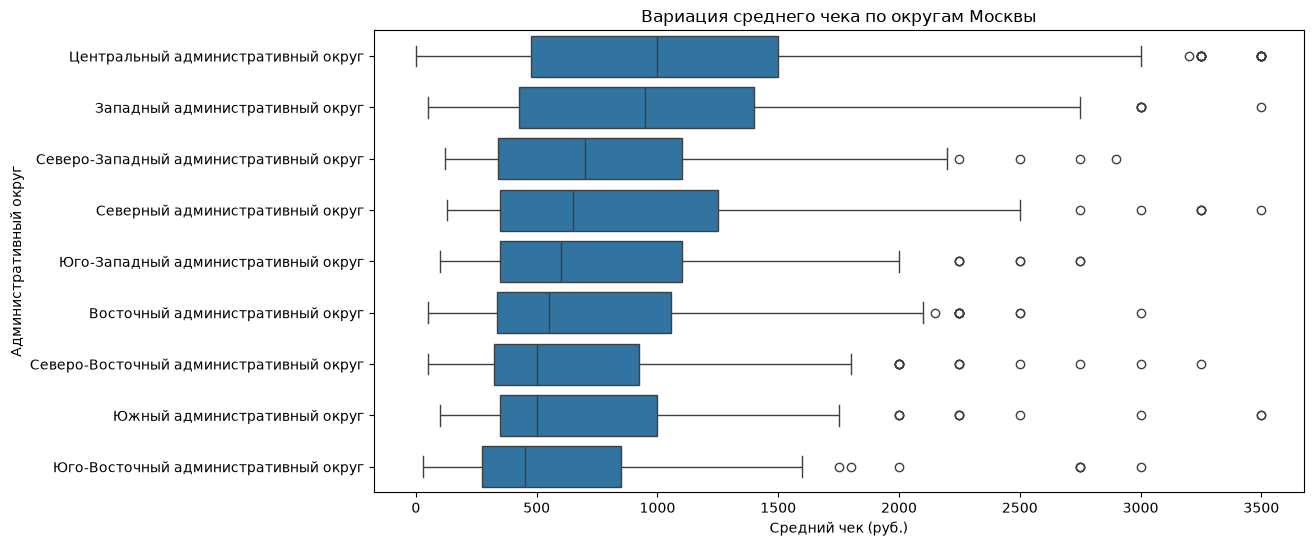

In [44]:
plt.figure(figsize = (12, 6))

# Установим лимит по 99-му процентилю, чтобы исключить аномально высокие значения среднего чека (и улучшить визульное восприятие):
max_limit = rest_cleaned['middle_avg_bill'].quantile(0.99)
filtered_avg_bill = rest_cleaned[rest_cleaned['middle_avg_bill'] < max_limit]

# Отсортируем округа по медиане для улучшения визульного восприятия: 
median_bill_order = filtered_avg_bill.groupby('district')['middle_avg_bill'].median().sort_values(ascending=False).index

# Построим ящики с усами:
sns.boxplot(data=filtered_avg_bill,
            x = 'middle_avg_bill',
            y = 'district',
            order = median_bill_order)

# Оформим график:
plt.title('Вариация среднего чека по округам Москвы')
plt.xlabel('Средний чек (руб.)')
plt.ylabel('Административный округ')

# Выведем наш график:
plt.show()

Дополнительно посчитаем разброс цен по округам:

In [45]:
# Посчитаем квартили и медиану:
district_bill_iqr = filtered_avg_bill.groupby('district')['middle_avg_bill'].quantile([0.25, 0.5, 0.75]).unstack()

# Переименуем столбцы для улучшения вызуального восприятия:
district_bill_iqr.columns = ['q1', 'median', 'q3']

# Посчитаем межквартильный размах (т.е. разброс цен):
district_bill_iqr['iqr'] = (district_bill_iqr['q3'] - district_bill_iqr['q1']).round(2)

# Отсортируем по убыванию разброса цен:
district_bill_iqr = district_bill_iqr.sort_values(by = 'iqr', ascending = False)

# Выведем нашу таблицу:
district_bill_iqr

,q1,median,q3,iqr
district,,,,
Центральный административный округ,475.0,1000.0,1500.0,1025.0
Западный административный округ,425.0,950.0,1400.0,975.0
Северный административный округ,350.0,650.0,1250.0,900.0
Северо-Западный административный округ,340.0,700.0,1100.0,760.0
Юго-Западный административный округ,350.0,600.0,1100.0,750.0
Восточный административный округ,336.0,550.0,1057.5,721.5
Южный административный округ,350.0,500.0,1000.0,650.0
Северо-Восточный административный округ,325.0,500.0,925.0,600.0
Юго-Восточный административный округ,275.0,450.0,850.0,575.0


**Итог:** Мы рассмотрели распределение среднего чека по округам, включая медианы, межквартильный размах, исключив аномально высокие значения по 99-му процентилю. Было установлено:
1. Самый высокий средний чек в Центральном и Западном округах. Медианный чек там составляет 1000 и 950 рублей соответственно, что в два раза больше среднего чека в Юго-Восточном округе, где медиана равна 450 рублям;
2. Что касается распределия среднего чека, Центральный и Западный округа имеют равномерный разброс цен (значения межквартильного размаха равны 1025,0 и 975,0). Это свидетельствует, что здесь можно найти бюджетные заведения, ровно как и дорогие;
3. В таких округах как Южный административный, Северо-Восточный и Юго-Восточный распределение значений среднего чека смещено в сторону невысоких чеков. Значения межквартильного размаха там минимальны (575,0, 600,0 и 575,0 рублей соответственно), а третьи квартили не превышают 1000 рублей, что говорит о концентрации заведений в бюджетном и средне-ценовом сегменте;
5. На графике во всех округах присутствуют изолированные точки в правой части. Это указывает на наличие заведений-выбросов с очень высоким средним чеком (от 1700 до 3500 рублей), которые выбиваются из общей массы даже в спальных районах Москвы.

[Вернуться к содержанию](#Содержание)

<a id="Результаты-исследовательского-анализа-данных"></a>
### Результаты исследовательского анализа данных

**Распределение заведений по категориям.**

Кафе и рестораны составляют основу рынка общественно питания Москвы, занимая в сумме более половины рынка (28,28% и 24,30% соответственно). Кофейни  идут следом (16,82%). Остальные категории остаются в меньшенстве: бары или пабы - 9,09%, пиццерии - 7,53%, заведения быстрого питания - 7,18%, столовые - 3,75%, а меньше всего булочных - 3,05%.
   
**Территориальное распределение заведений.**

Подавляющее число заведений размещено в Центральном административном округе 26,68%. Следующее по численности значение в Северном административном округе - 10,69%. В остальных административных округах количество заведений находится в диапозоне от 8,4 до 10,7%. А меньше всего в Северо-Западном - 4,87%.

Объяснить такую плотность объектов общественного питания в Центральном административном округе несложно. Район является главным историческим, политическим, деловым и культурным местом Москвы: здесь и Кремль, и Дом Правительства, и Красная площадь, и "Москва-Сити", и Большой театр, и Третьяковская галерея, и много чего ещё интересного.

В ЦАО большое количество ресторанов - 29,88%. Следом идут: `кафе` - 20,70%, `кофейни` - 19,09%, `бары и пабы` - 16,24%, `пиццерии` - 5,04%, `заведения быстрого питания` - 3,88%, `столовые` - 2,94%, `булочные` - 2,23%. Отметим, ЦАО заметно отличается от остальных районов: здесь рестораны обходят кафе по популярности, а доля баров и пабов почти вдвое превышает средний показатель по городу. Несложно объяснить эти цифры - здесь большой поток платежеспособной аудитории, которая приезжает сюда работать, отдыхать и тратить деньги.

**Соотношение сетевых и несетевых заведений.**

`Несетевые заведения` (61,9%) заметно преобладают над `сетевыми` (38,1%).

Чаще всего сетевыми бывают: `булочные` (61,33% булочных - сетевые), затем `пиццерии` (52,13% сетевых), следом `кофейни` (50,96% сетевых), `заведения быстрого питания` (38,47% сетевых), `рестораны` (35,70% сетевых), `кафе` (32,79% сетевых), `столовые` (27,94% сетевых), `бары и пабы` (21,99% сетевых).

**Посадочные места.**

В процессе анализа нам встретились аномальные значения и мы посчитали, что все значения выше 99-го процентиля - это 625 посадочных мест (банкетные залы) - будут для нас выбросами. Всего мы насчитали 30 таких значений, появление которых мы решили объяснить ошибочным вводом данных на сервисах Яндекса.

Далее мы определили типичное количество посадочных мест в зависимости от категории заведения. Под типичным количеством мы приняли считать медианное значение, так как такой способ минимизирует влияние выбросов на итоговое значение. Получили следующее распределение: `ресторан` - 86; `бар,паб` - 82; `кофейня` - 80; `столовая` - 75-76; `заведения быстрого питания` - 65; `кафе` - 60; `пиццерия` - 55; `булочная` - 50.

**Взаимосвязь рейтинга с другими данными.**

Средние оценки заведений по категориям находятся примерно на одном уровне: `бар/паб` - 4,39; `пиццерия` - 4,30; `ресторан` - 4,29; `кофейня` - 4,28; `булочная` - 4,27; `столовая` - 4,21; `кафе` - 4,12; `заведения быстрого питания` - 4,05. Далее мы исследовали корреляцию по другим данным (считали коэффициент `phi_k`) и установили, что сильнее всего на рейтинг влияет ценовая категория заведения (коэффициент `phi_k` равняется 0,28). Следующая по силе взаимосвязь с расположением заведения - 0,20. Затем с категорией заведения - 0,19. Потом с признаком "круглосуточности" заведения - 0,15. Далее с тем, является заведение сетевым или нет - 0,11. Нулевая взаимосвязь рейтинга с количеством посадочных мест - 0,00.

Также была проверена сильнейшая взаимосвязь: с ростом ценовой категории увеличивается средний рейтинг заведения. Заведения с высоким чеком имеют более высокий средний балл (4,44), в то время как бюджетный сегмент оценивается ниже (4,17).

**Топ-15 популярных сетей в Москве.**

Мы получили следующий топ-15 популярных сетей в Москве (под популярностью мы имеем в виду количество заведений сети):
1. `шоколадница` — 120 заведений, средняя оценка 4,18;
2. `домино'с пицца` — 77 заведений, средняя оценка 4,17;
3. `додо пицца` — 74 заведения, средняя оценка 4,29;
4. `one price coffee` — 72 заведения, средняя оценка 4,07;
5. `яндекс лавка` — 69 заведений, средняя оценка 3,87;
6. `cofix` — 65 заведений, средняя оценка 4,08;
7. `prime` — 50 заведений, средняя оценка 4,12;
8. `хинкальная` — 44 заведения, средняя оценка 4,32;
9. `шаурма` — 43 заведения, средняя оценка 3,91;
10. `кофепорт` — 42 заведения, средняя оценка 4,15;
11. `кулинарная лавка братьев караваевых` — 39 заведений, средняя оценка 4,39;
12. `теремок` — 38 заведений, средняя оценка 4,12;
13. `чайхана` — 37 заведений, средняя оценка 3,92;
14. `cofefest` — 32 заведения, средняя оценка 3,98;
15. `буханка` — 32 заведения, средняя оценка 4,40.

В рамках этого топа мы определили доли категорий заведений:
- `кофейни` - 33,3%;
- `ресторан` - 20,0%;
- `кафе` - 13,3%;
- `заведения быстрого питания` - 13,3%;
- `пиццерии` - 13,3%;
- `булочные` - 6,7%.

**Вариации среднего чека в зависимости от округа.**

Мы рассмотрели распределение среднего чека по округам, включая медианы, межквартильный размах, исключив аномально высокие значения по 99-му процентилю. Было установлено:

1. Самый высокий средний чек в Центральном и Западном округах. Медианный чек там составляет 1000 и 950 рублей соответственно, что в два раза больше среднего чека в Юго-Восточном округе, где медиана равна 450 рублям;
2. Центральный и Западный округа имеют равномерный разброс цен (значения межквартильного размаха равны 1025 и 975). Это свидетельствует, что здесь можно найти бюджетные заведения, ровно как и дорогие;
3. В Южном административный, Северо-Восточном и Юго-Восточном округах распределение значений среднего чека смещено в сторону невысоких чеков. Значения межквартильного размаха там минимальны (575,0, 600,0 и 575,0 рублей соответственно), а третьи квартили не превышают 1000 рублей, что говорит о концентрации заведений в бюджетном и средне-ценовом сегменте;
5. Было установлено наличие заведений-выбросов с очень высоким средним чеком (от 1700 до 3500 рублей), которые выбиваются из общей массы даже в спальных районах Москвы.

[Вернуться к содержанию](#Содержание)

<a id="Итоговый-вывод-и-рекомендации"></a>
## Итоговый вывод и рекомендации

<a id="Краткий-обзор-проделанной-работы"></a>
### Краткий обзор проделанной работы

В ходе проекта был проведен  исследовательский анализ рынка общественного питания Москвы на основе данных из сервисов Яндекс Карт и Яндекс Бизнеса. Первоначальные датасеты `rest_info` и `rest_price` были объединены в `rest_merged` из 8406 строк. На этапе предобработки были устранены неявные дубликаты (их было 4), обработаны пропущенные значения в `price` и `hours` (заполнены текстовые пропуски категорией "не указано"), удален малоинформативный столбец `middle_coffee_cup` и добавлен столбец с бинарным признаком круглосуточной работы заведения `is_24_7`. Был сформирован очищенный датафрейм `rest_cleaned`. Также данные были очищены от экстремальных выбросов по количеству мест (за границу взят 99-й процентиль).

[Вернуться к содержанию](#Содержание)

<a id="Выводы-исследования"></a>
### Выводы исследования

1. Кафе (28,28%) и рестораны (24,30%) занимают больше половины рынка общественного питания Москвы. При этом сетевой сегмент составляет всего 38,1%, уступая несетевым заведениям (61,9%). Чаще всего сетевыми бывают булочные (61,33% булочных - сетевые), пиццерии (52,13% сетевых) и кофейни (50,96% сетевых).
2. В Центральном административном округе размещено 26,68% всех заведений города. Здесь больше всего ресторанов - 29,88%, а доля баров и пабов (16,24%) почти вдвое выше, чем в среднем по Москве.
3. Заведения в ЦАО и ЗАО имеют более высокий средний чек (950-1000 рублей), чем в остальных округах (450–650 рублей). За пределами центра больше заведений в бюджетном сегменте. В ЦАО и ЗАО же распределение равномерное, т.е. можно найти как дорогое, так и бюджетное.
4. На основе расчета матрицы корреляции было установлено, что сильнее всего на рейтинг заведения влияет его ценовая категория (0,28), а также район (0,20) и категория (0,19). Была обнаружена прямая зависимость: чем выше ценовой сегмент, тем выше средний рейтинг. Заведения с большим чеком имеют средний балл 4,44, а заведения с низкой ценовой категорией - 4,17. Количество посадочных мест никак не влияет на рейтинг заведения (корреляция 0,00).
5. Самые высокие рейтинг у баров и пабов (4,39), за ними идут пиццерии (4,30), рестораны (4,29), кофейни (4,28), булочные (4,27), столовые (4,21), кафе (4,12) и заведения быстрого питания (4,05).
6. Медианное количество мест сильно варьируется: от 50–60 мест для булочных и кафе до 82–86 мест для баров и ресторанов.

[Вернуться к содержанию](#Содержание)

<a id="Рекомендации-инвесторам"></a>
### Рекомендации инвесторам

Первый вариант (с высокой  конкуренцией) — это дорогой несетевой ресторан, расположенный в Центральном округе Москвы, примерно на 85-90 мест. Здесь большой поток платежеспособной аудитории, которая приезжает сюда работать, отдыхать и тратить деньги. Высокие цены также позволят обеспечить высокий уровень обслуживания, что обеспечит заведению высокий рейтинг.

Второй вариант (с высокой конкуренцией) — открыть бар или паб, расположенный в Центральном округе Москвы, примерно на 80-85 мест. Бары в Москве получают самые высокие рейтинги в сравнении с другими категориями заведений. В центре развита культура отдыха, поэтому можно сделать заведение круглосуточным. Ровно как в случае с ресторанами, рекомендуем сделать дорогое меню.

Третий вариант - это покупка франшизы кофейни с высокой популярностью, например, `one price coffee` или `cofix`, с расположением не в центре, а, например, в спальных районах. Кофейни занимают 33,3% в топ-15 популярных сетей, что доказывает лояльность клиентов в Москве к данной категории заведений. В свою очередь, популярность сетей и невысокий чек (до 300 рублей) обеспечат приток клиентов.

Четвертый вариант схож с третим - это небольшая кофейня на 30 мест (рекомендуем такое количество мест для создания уюта, а также ввиду не такого большого потока клиентов) в спальном районе. С умеренным чеком в 200–300 рублей здесь можно легко занять свободную нишу без жесткой конкуренции.

[Вернуться к содержанию](#Содержание)